# QUBO Portfolio Optimisation — Result Analysis

**Experiment:** `experiment_results_20260426_184838.csv`  
**Strategies compared:** QUBO (Simulated-Annealing) · MPT (Mean-Variance)  
**Markets:** India · USA · Europe · Japan · Crypto  
**Parameters swept:** Universe size · Cardinality (B) · Correlation penalty (q) · Lookback window

---

## 1  Imports & Display Settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ── aesthetics ──────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
PALETTE   = {"QUBO": "#2196F3", "MPT": "#FF9800"}
MPALETTE  = sns.color_palette("tab10", 5)
MARKETS   = ["india", "usa", "europe", "japan", "crypto"]

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 60)
print("Dependencies loaded ✓")

Dependencies loaded ✓


## 2  Load & Inspect Dataset

In [2]:
CSV_PATH = r"C:\Users\Vivek\projects\PortfolioOptimization\results\experiment_results_20260427_034607.csv"

raw = pd.read_csv(CSV_PATH)
print(f"Shape : {raw.shape[0]:,} rows × {raw.shape[1]} columns")
print(f"Strategies : {sorted(raw['strategy'].unique())}")
print(f"Markets    : {sorted(raw['market'].unique())}")
print()
raw.head(3)

Shape : 2,025 rows × 49 columns
Strategies : ['EqualWeight', 'MPT', 'QUBO']
Markets    : ['crypto', 'europe', 'india', 'japan', 'usa']



,strategy,market,universe_size,B,q,lookback,selected_assets,tickers,weights,test_prices,qubo_energy,cardinality_violated,raw_count,lambda_used,use_garch_lambda,div_penalty,avg_pairwise_corr,sharpe_ratio,volatility,ann_return,total_return,max_drawdown,oos_n_days,diversification_ratio,exante_sharpe,exante_expected_return,exante_vol,reliability_flag,diag_lambda,diag_obj_scale,diag_ratio,diag_check1_ratio_ok,diag_mid_vs_high_overlap,diag_mid_vs_low_overlap,diag_check2_sensitivity_ok,diag_energy_B,diag_energy_Bp1,diag_energy_gap,diag_check3_gap_ok,diag_all_ok,universe_label,rfr_adj_ann_return,n_rebalances,config,conc_n_positions,conc_effective_n,conc_max_weight,conc_top3_weight,effective_positions
0,QUBO,india,10,2,0.3000,126,"['INFY.NS', 'ITC.NS']","['RELIANCE.NS', 'HDFCBANK.NS', 'HINDUNILVR.NS'...",[0. 0. 0. 0.5 0. 0. 0. 0. 0.5 0. ],Ticker RELIANCE.NS HDFCBANK.NS HINDUNIL...,-6.0779,0.0000,2.0000,1.2759,True,0.3000,0.2866,-1.0810,0.1529,-0.1059,-0.1055,-0.2063,251,1.2444,1.5060,0.3159,0.1666,RELIABLE,1.2291,1.2291,3.0000,True,1.0000,1.0000,True,-5.8906,-4.3068,1.5838,True,True,u10,-0.1709,1.0000,u10|B=2|q=0.3|lb=126,2,2.0000,0.5000,1.0000,NaN
1,MPT,india,10,2,0.3000,126,"['HDFCBANK.NS', 'INFY.NS', 'BHARTIARTL.NS', 'I...","['RELIANCE.NS', 'HDFCBANK.NS', 'HINDUNILVR.NS'...",[2.64587280e-11 1.13762393e-01 9.17565737e-11 ...,Ticker RELIANCE.NS HDFCBANK.NS HINDUNIL...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.7711,0.1361,-0.0480,-0.0478,-0.1664,251,1.4233,1.4887,0.2819,0.1457,RELIABLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,u10,-0.1130,NaN,u10|B=2|q=0.3|lb=126,4,2.9379,0.4000,0.9138,4.0000
2,EqualWeight,india,10,2,0.3000,126,NaN,"['RELIANCE.NS', 'HDFCBANK.NS', 'HINDUNILVR.NS'...",[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1],Ticker RELIANCE.NS HDFCBANK.NS HINDUNIL...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0029,0.1209,0.1960,0.1951,-0.0763,251,1.7048,-0.5853,-0.0090,0.1264,RELIABLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,u10,0.1310,NaN,u10|B=2|q=0.3|lb=126,10,10.0000,0.1000,0.3000,NaN


In [3]:
raw.describe(include=[np.number]).T[["count","mean","std","min","50%","max"]].round(4)

,count,mean,std,min,50%,max
universe_size,2025.0000,29.9067,14.0160,10.0000,30.0000,50.0000
B,2025.0000,9.0000,5.0345,2.0000,8.0000,20.0000
q,2025.0000,0.5000,0.1633,0.3000,0.5000,0.7000
lookback,2025.0000,294.0000,157.1884,126.0000,252.0000,504.0000
qubo_energy,675.0000,-11.8506,8.7662,-40.3649,-9.8529,31.3288
cardinality_violated,675.0000,0.5333,0.4993,0.0000,1.0000,1.0000
raw_count,675.0000,7.6756,4.0797,2.0000,7.0000,20.0000
lambda_used,675.0000,0.2631,0.2454,0.0406,0.1783,1.6912
div_penalty,675.0000,0.3000,0.0000,0.3000,0.3000,0.3000
avg_pairwise_corr,675.0000,0.2245,0.1078,0.0149,0.1904,0.6204


In [4]:
# Missing value map
null_counts = raw.isnull().sum()
null_pct    = (null_counts / len(raw) * 100).round(1)
null_df = pd.DataFrame({"missing_count": null_counts, "missing_%": null_pct})
null_df = null_df[null_df["missing_count"] > 0].sort_values("missing_%", ascending=False)
print(f"Columns with any NaN: {len(null_df)}")
null_df

Columns with any NaN: 22


,missing_count,missing_%
qubo_energy,1350,66.7000
cardinality_violated,1350,66.7000
lambda_used,1350,66.7000
raw_count,1350,66.7000
use_garch_lambda,1350,66.7000
div_penalty,1350,66.7000
diag_check2_sensitivity_ok,1350,66.7000
avg_pairwise_corr,1350,66.7000
diag_lambda,1350,66.7000
diag_obj_scale,1350,66.7000


## 3  Data Cleaning & Feature Engineering

In [5]:
df = raw.copy()

# ── boolean coercion ────────────────────────────────────────────────────────
bool_cols = ["diag_check1_ratio_ok", "diag_check2_sensitivity_ok",
             "diag_check3_gap_ok", "diag_all_ok"]
for c in bool_cols:
    df[c] = df[c].map({"True": True, "False": False, True: True, False: False})

# ── universe label ordering ──────────────────────────────────────────────────
ulabel_order = ["u10", "u20", "u30", "u40", "u50"]
df["universe_label"] = pd.Categorical(df["universe_label"], categories=ulabel_order, ordered=True)

# ── strategy ordering ────────────────────────────────────────────────────────
strat_order = ["QUBO", "MPT"]
df["strategy"] = pd.Categorical(df["strategy"], categories=strat_order, ordered=True)

# ── derived columns ──────────────────────────────────────────────────────────
df["calmar_ratio"]     = df["ann_return"] / df["max_drawdown"].abs().replace(0, np.nan)
df["return_per_vol"]   = df["ann_return"] / df["volatility"].replace(0, np.nan)
df["excess_sharpe"]    = df["sharpe_ratio"] - df.groupby("market")["sharpe_ratio"].transform("mean")

qubo_mask = df["strategy"] == "QUBO"
df["diag_ok_str"] = "N/A"
df.loc[qubo_mask, "diag_ok_str"] = df.loc[qubo_mask, "diag_all_ok"].map({True: "PASS", False: "FAIL"})

print("Cleaning complete.")
print(f"  Rows             : {len(df):,}")
print(f"  QUBO rows        : {qubo_mask.sum():,}")
print(f"  QUBO diag pass   : {df.loc[qubo_mask,'diag_all_ok'].sum()} / {qubo_mask.sum()}")
df.dtypes.value_counts()

Cleaning complete.
  Rows             : 2,025
  QUBO rows        : 675
  QUBO diag pass   : 660 / 675


float64     33
str          8
int64        5
object       5
category     1
category     1
Name: count, dtype: int64

## 4  Strategy Performance Summary

Key metrics aggregated by strategy across all markets and parameter configurations.


In [6]:
PERF_METRICS = ["sharpe_ratio","ann_return","rfr_adj_ann_return",
                "volatility","max_drawdown","diversification_ratio",
                "exante_sharpe","calmar_ratio"]

summary = (df.groupby("strategy")[PERF_METRICS]
             .agg(["mean","median","std"])
             .round(4))
summary

sharpe_ratio               ann_return                \
                 mean median    std       mean median    std   
strategy                                                       
QUBO           0.5083 0.5621 0.5286     0.1477 0.1455 0.1650   
MPT            0.5225 0.5430 0.5272     0.1591 0.1410 0.1697   

         rfr_adj_ann_return               volatility                \
                       mean median    std       mean median    std   
strategy                                                             
QUBO                 0.1170 0.1176 0.1605     0.2762 0.2551 0.0910   
MPT                  0.1284 0.1138 0.1664     0.2831 0.2591 0.0892   

         max_drawdown                diversification_ratio                \
                 mean  median    std                  mean median    std   
strategy                                                                   
QUBO          -0.2419 -0.2336 0.0742                1.4924 1.4877 0.1297   
MPT           -0.2470 -0.2441 0.0704                1.4764 1.4705 0.1067   

         exante_sharpe               calmar_ratio                
                  mean median    std         mean median    std  
strategy                                                         
QUBO            2.2092 2.3707 0.9302       0.7283 0.6330 0.7499  
MPT             2.2112 2.3948 0.9161       0.7453 0.6952 0.7552

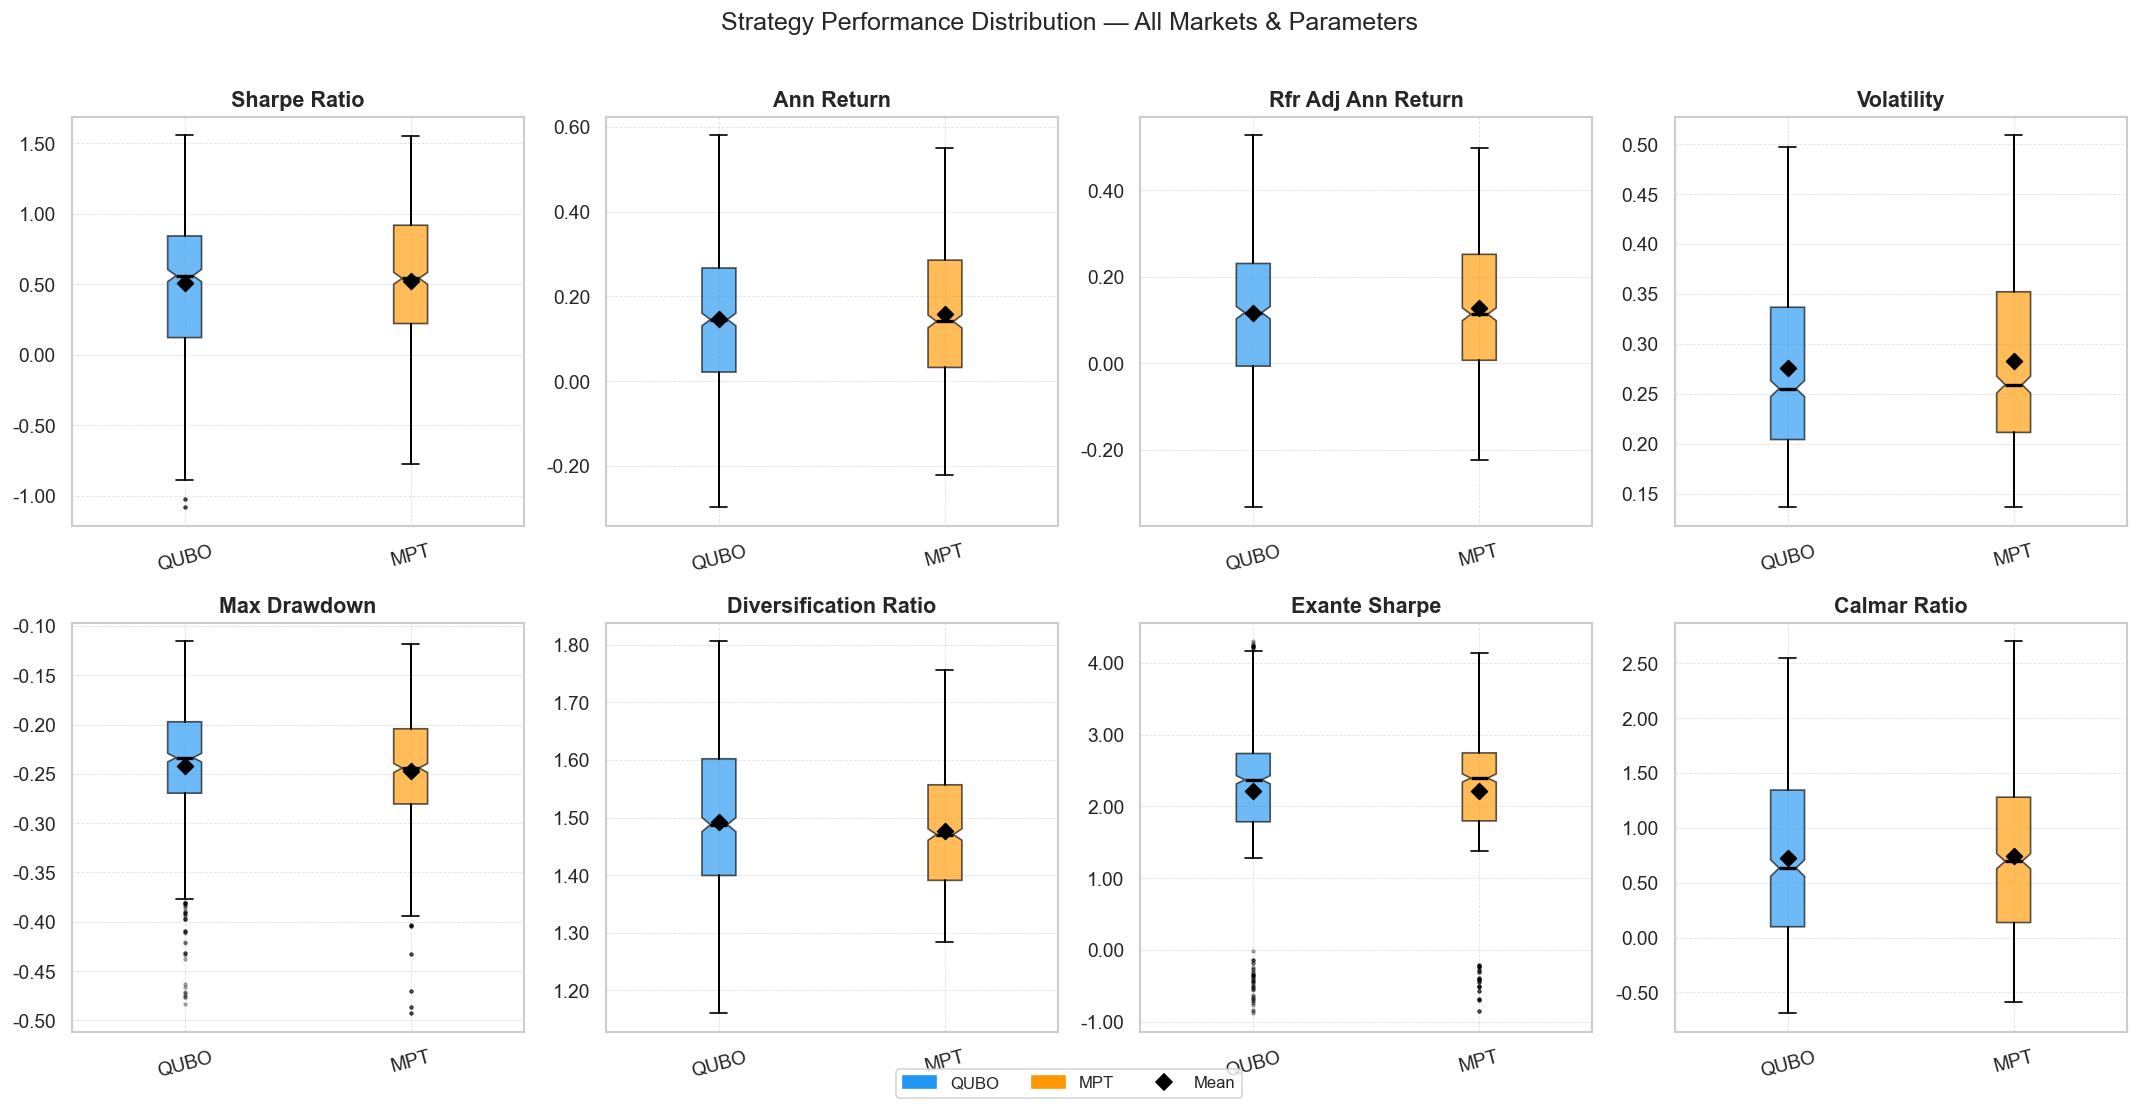

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for ax, metric in zip(axes, PERF_METRICS):
    data   = [df[df["strategy"] == s][metric].dropna() for s in strat_order]
    colors = [PALETTE[s] for s in strat_order]
    bp     = ax.boxplot(data, patch_artist=True, notch=True,
                        medianprops=dict(color="black", linewidth=2),
                        whiskerprops=dict(linewidth=1.2),
                        flierprops=dict(marker=".", markersize=3, alpha=0.4))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color); patch.set_alpha(0.65)

    # overlay means
    means = [d.mean() for d in data]
    ax.scatter(range(1, len(strat_order)+1), means, color="black",
               marker="D", s=45, zorder=5, label="Mean")

    ax.set_xticks(range(1, len(strat_order)+1))
    ax.set_xticklabels(strat_order, rotation=15)
    ax.set_title(metric.replace("_", " ").title())
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.2f"))
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)

# shared legend
legend_handles = [Patch(color=PALETTE[s], label=s) for s in strat_order]
legend_handles.append(Line2D([0],[0], marker="D", color="black", markersize=7, label="Mean", linestyle="None"))
fig.legend(handles=legend_handles, loc="lower center", ncol=4, fontsize=10, frameon=True)

fig.suptitle("Strategy Performance Distribution — All Markets & Parameters", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

## 5  Market-wise Performance Analysis

In [8]:
market_summary = (df.groupby(["market","strategy"])
                    [["sharpe_ratio","ann_return","volatility","max_drawdown","rfr_adj_ann_return"]]
                    .mean().round(4).unstack("strategy"))
market_summary

sharpe_ratio        ann_return        volatility        max_drawdown  \
strategy         QUBO    MPT       QUBO    MPT       QUBO    MPT         QUBO   
market                                                                          
crypto         0.1816 0.2229    -0.0121 0.0049     0.4224 0.4208      -0.3575   
europe         0.3418 0.3176     0.0943 0.0918     0.2216 0.2280      -0.2398   
india          0.2061 0.1944     0.0980 0.0949     0.1704 0.1753      -0.1617   
japan          0.7688 0.8097     0.2108 0.2354     0.2972 0.3101      -0.2189   
usa            1.0430 1.0679     0.3474 0.3685     0.2692 0.2815      -0.2318   

                 rfr_adj_ann_return         
strategy     MPT               QUBO    MPT  
market                                      
crypto   -0.3491            -0.0121 0.0049  
europe   -0.2462             0.0593 0.0568  
india    -0.1663             0.0330 0.0299  
japan    -0.2322             0.2098 0.2344  
usa      -0.2410             0.2949 0.3160

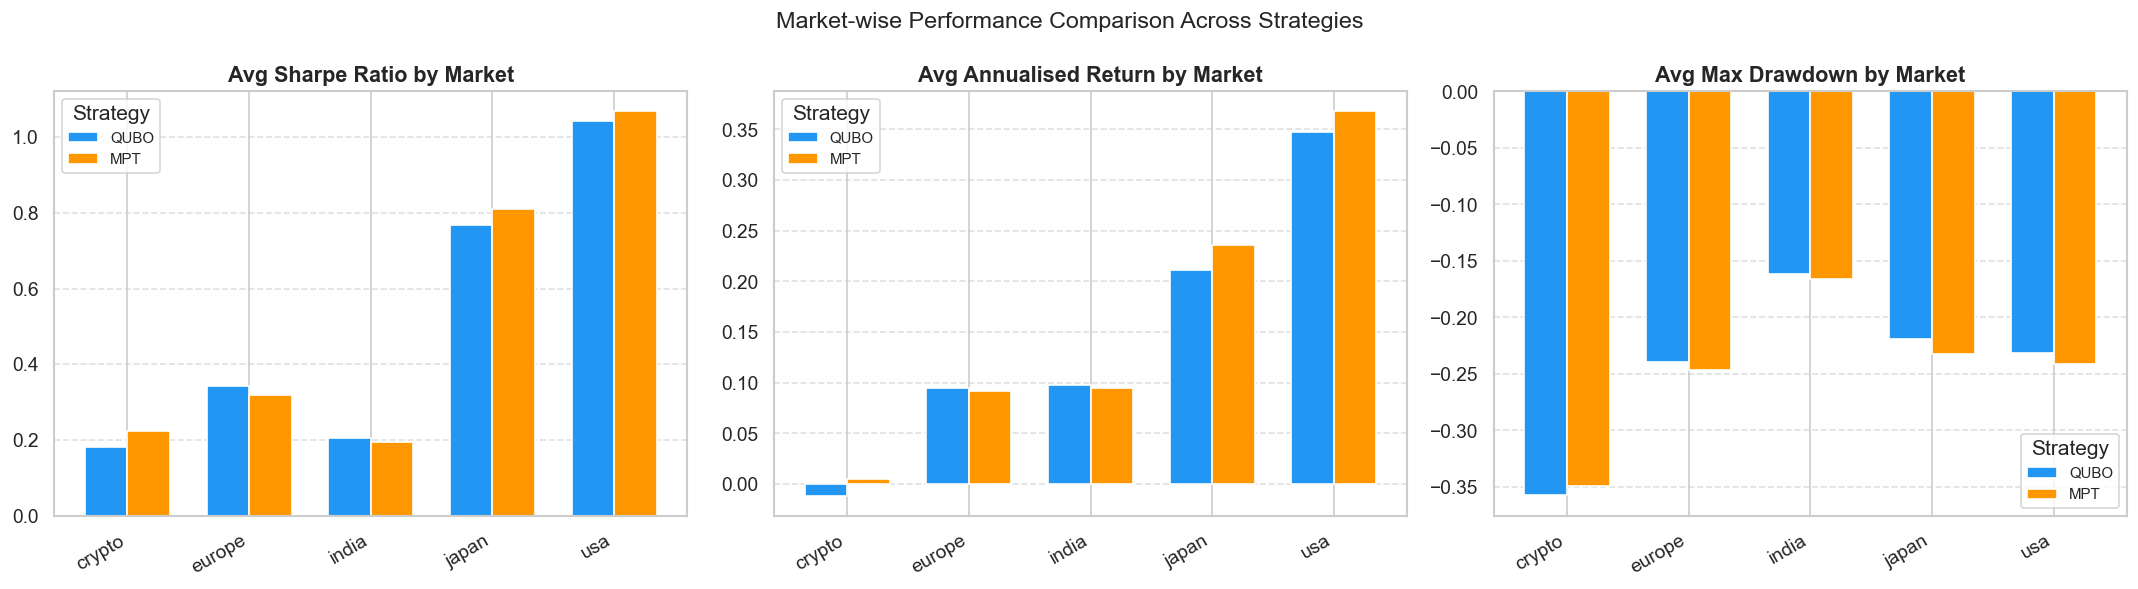

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics_show = ["sharpe_ratio", "ann_return", "max_drawdown"]
titles       = ["Sharpe Ratio", "Annualised Return", "Max Drawdown"]

for ax, metric, title in zip(axes, metrics_show, titles):
    mkt_data = df.groupby(["market","strategy"])[metric].mean().unstack("strategy")[strat_order]
    mkt_data.plot(kind="bar", ax=ax, color=[PALETTE[s] for s in strat_order],
                  edgecolor="white", width=0.7)
    ax.set_title(f"Avg {title} by Market")
    ax.set_xlabel("")
    ax.set_xticklabels(mkt_data.index, rotation=30, ha="right")
    ax.legend(title="Strategy", fontsize=9)
    ax.grid(True, axis="y", linestyle="--", alpha=0.6)

fig.suptitle("Market-wise Performance Comparison Across Strategies", fontsize=14)
plt.tight_layout()
plt.show()

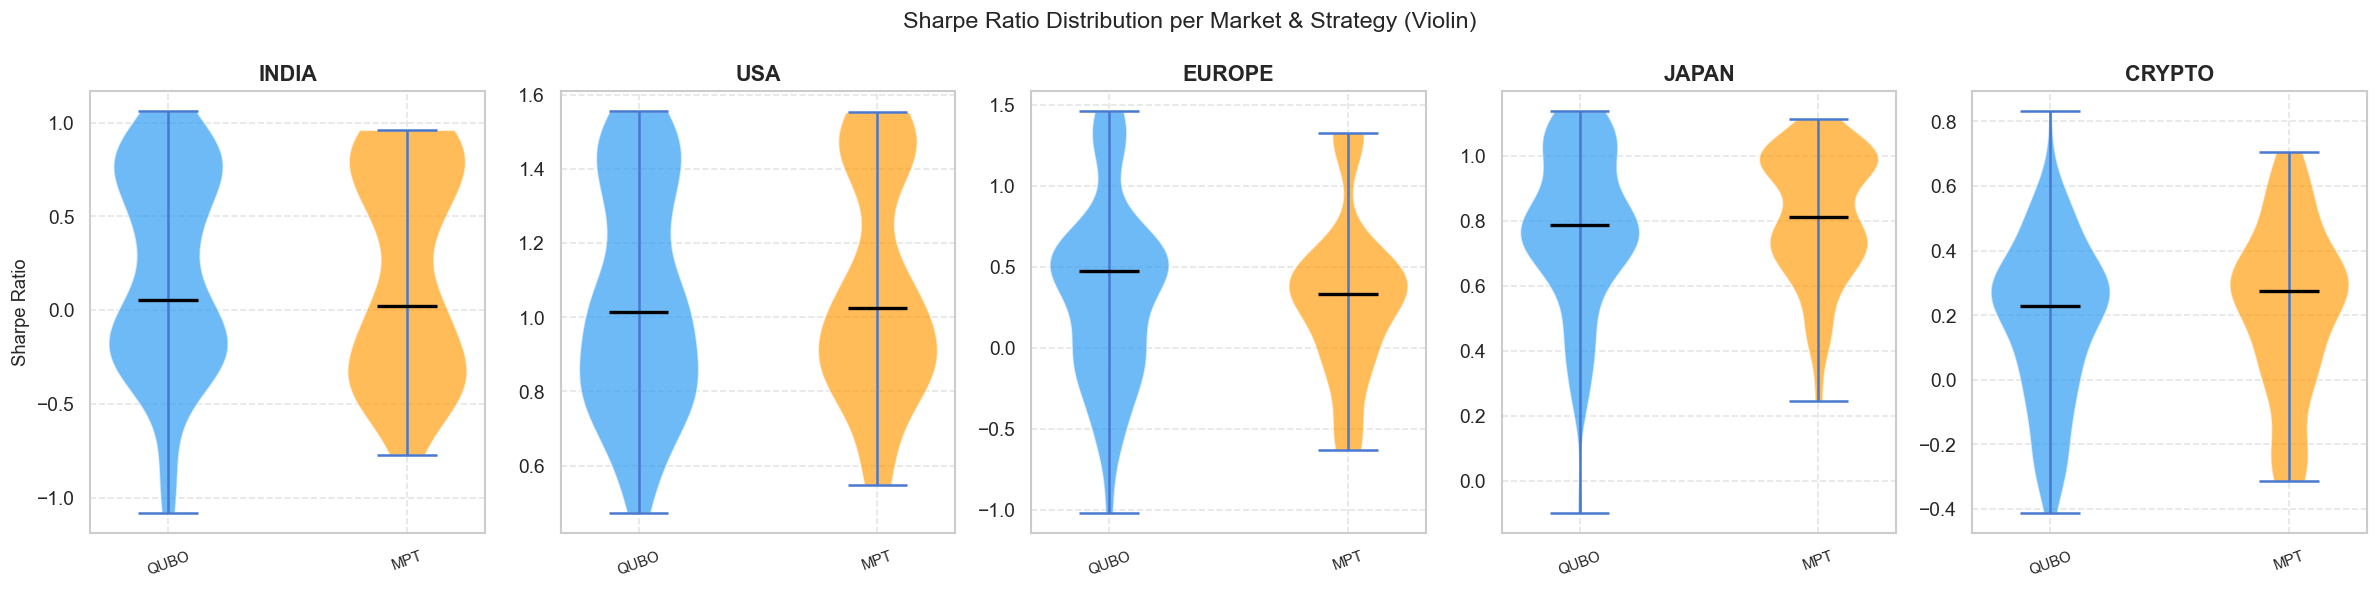

In [10]:
# Sharpe ratio violin per market
fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharey=False)

for ax, market in zip(axes, MARKETS):
    sub = df[df["market"] == market]
    data   = [sub[sub["strategy"] == s]["sharpe_ratio"].dropna() for s in strat_order]
    colors = [PALETTE[s] for s in strat_order]
    parts  = ax.violinplot(data, positions=range(len(strat_order)),
                           showmedians=True, showmeans=False)
    for pc, color in zip(parts["bodies"], colors):
        pc.set_facecolor(color); pc.set_alpha(0.65)
    parts["cmedians"].set_color("black"); parts["cmedians"].set_linewidth(2)
    ax.set_title(market.upper())
    ax.set_xticks(range(len(strat_order)))
    ax.set_xticklabels(strat_order, rotation=20, fontsize=9)
    ax.set_ylabel("Sharpe Ratio" if ax == axes[0] else "")
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Sharpe Ratio Distribution per Market & Strategy (Violin)", fontsize=14)
plt.tight_layout()
plt.show()

## 6  Risk-Return Landscape & Pareto Frontier

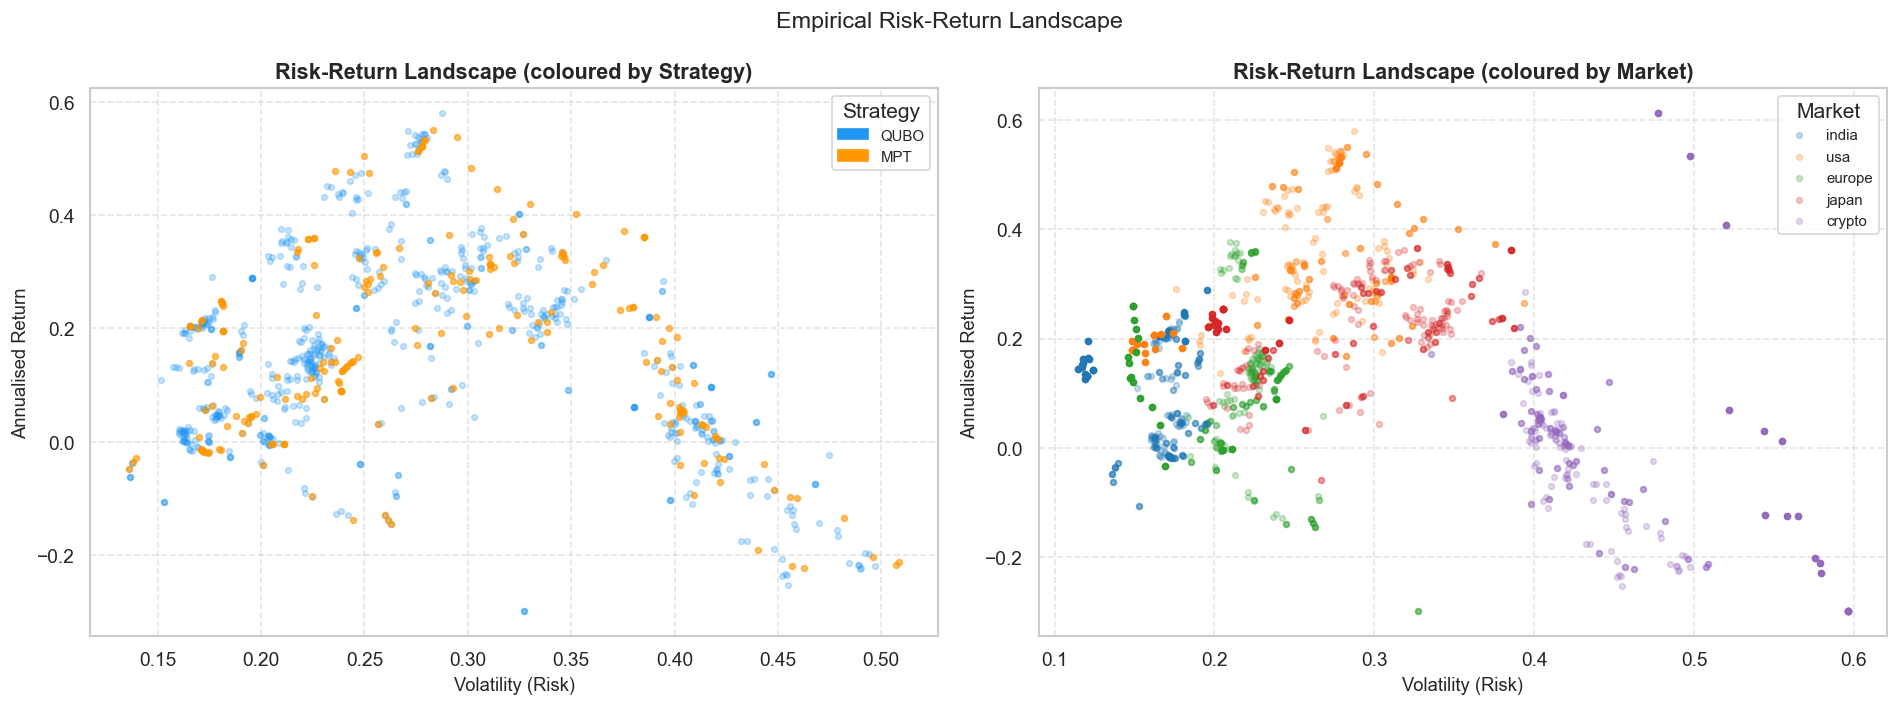

In [11]:
# Filter outliers for cleaner plot (vol < 1.5, |ann_return| < 1.0)
plot_df = df[(df["volatility"] < 1.5) & (df["ann_return"].abs() < 1.0)].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── LEFT: coloured by strategy ───────────────────────────────────────────────
ax = axes[0]
for strat in strat_order:
    sub = plot_df[plot_df["strategy"] == strat]
    ax.scatter(sub["volatility"], sub["ann_return"],
               color=PALETTE[strat], alpha=0.25, s=12, label=strat)
handles = [Patch(color=PALETTE[s], label=s) for s in strat_order]
ax.legend(handles=handles, title="Strategy", fontsize=9)
ax.set_xlabel("Volatility (Risk)"); ax.set_ylabel("Annualised Return")
ax.set_title("Risk-Return Landscape (coloured by Strategy)")
ax.grid(True, linestyle="--", alpha=0.5)

# ── RIGHT: coloured by market ────────────────────────────────────────────────
ax = axes[1]
mkt_colors = dict(zip(MARKETS, MPALETTE))
for mkt in MARKETS:
    sub = plot_df[plot_df["market"] == mkt]
    ax.scatter(sub["volatility"], sub["ann_return"],
               color=mkt_colors[mkt], alpha=0.25, s=12, label=mkt)
ax.legend(title="Market", fontsize=9)
ax.set_xlabel("Volatility (Risk)"); ax.set_ylabel("Annualised Return")
ax.set_title("Risk-Return Landscape (coloured by Market)")
ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Empirical Risk-Return Landscape", fontsize=14)
plt.tight_layout()
plt.show()

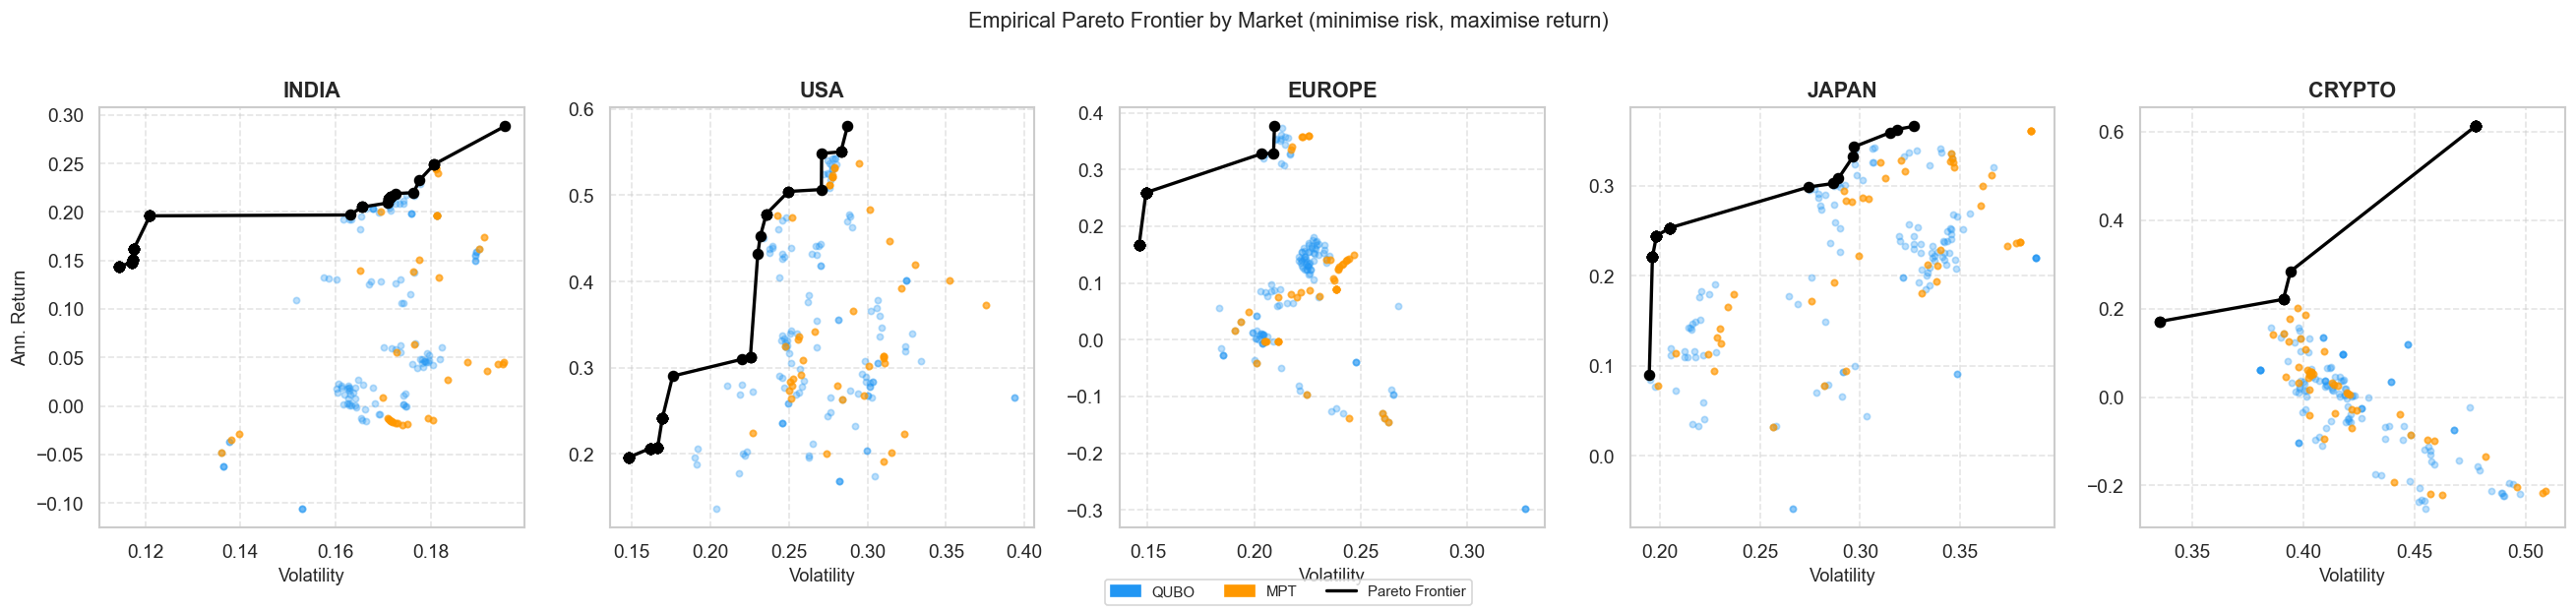

In [12]:
def pareto_front(df_in, x_col="volatility", y_col="ann_return"):
    """Return rows on the Pareto frontier (minimise x, maximise y)."""
    pts = df_in[[x_col, y_col]].dropna().values
    idx = df_in[[x_col, y_col]].dropna().index
    pareto_idx = []
    for i, (xi, yi) in enumerate(pts):
        dominated = any(
            (pts[j, 0] <= xi) and (pts[j, 1] >= yi) and
            ((pts[j, 0] < xi) or (pts[j, 1] > yi))
            for j in range(len(pts)) if j != i
        )
        if not dominated:
            pareto_idx.append(idx[i])
    return df_in.loc[pareto_idx].sort_values(x_col)

fig, axes = plt.subplots(1, 5, figsize=(22, 5), sharey=False)

for ax, market in zip(axes, MARKETS):
    sub = plot_df[plot_df["market"] == market].copy()
    pf  = pareto_front(sub)

    for strat in strat_order:
        s = sub[sub["strategy"] == strat]
        ax.scatter(s["volatility"], s["ann_return"],
                   color=PALETTE[strat], alpha=0.3, s=14)

    ax.plot(pf["volatility"], pf["ann_return"],
            color="black", linewidth=2, zorder=5, label="Pareto")
    ax.scatter(pf["volatility"], pf["ann_return"],
               color="black", s=35, zorder=6)

    ax.set_title(market.upper()); ax.set_xlabel("Volatility")
    ax.set_ylabel("Ann. Return" if ax == axes[0] else "")
    ax.grid(True, linestyle="--", alpha=0.5)

legend_h  = [Patch(color=PALETTE[s], label=s) for s in strat_order]
legend_h += [Line2D([0],[0], color="black", linewidth=2, label="Pareto Frontier")]
fig.legend(handles=legend_h, loc="lower center", ncol=4, fontsize=9, frameon=True)
fig.suptitle("Empirical Pareto Frontier by Market (minimise risk, maximise return)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

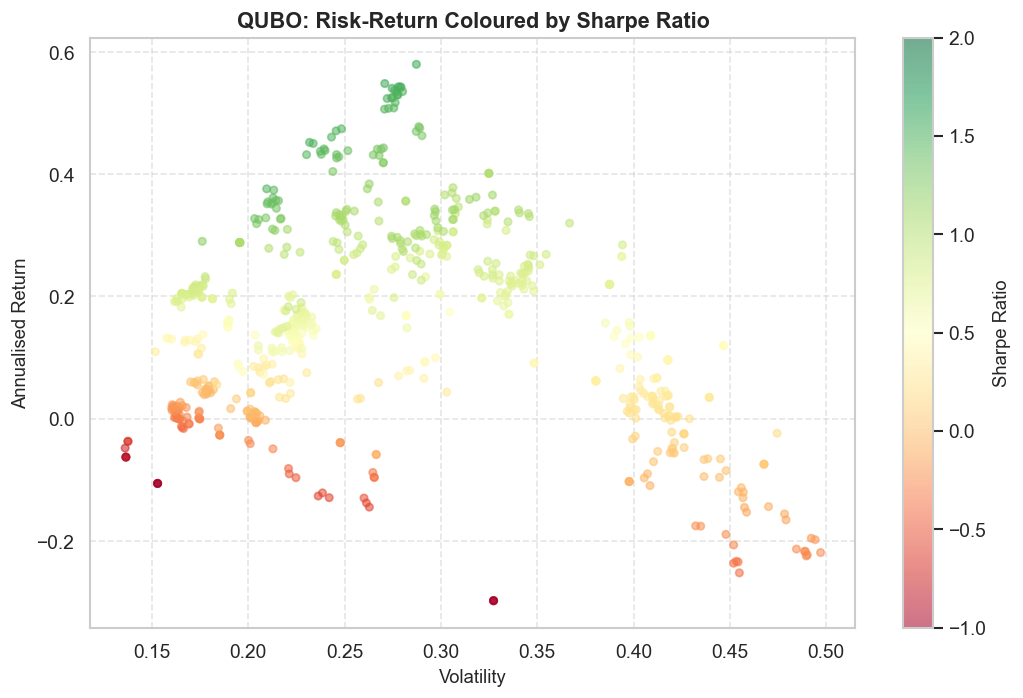

In [13]:
# Sharpe-coloured scatter
sc_df = plot_df[plot_df["strategy"] == "QUBO"].copy()

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(sc_df["volatility"], sc_df["ann_return"],
                c=sc_df["sharpe_ratio"], cmap="RdYlGn",
                alpha=0.55, s=20, vmin=-1, vmax=2)
plt.colorbar(sc, ax=ax, label="Sharpe Ratio")
ax.set_xlabel("Volatility"); ax.set_ylabel("Annualised Return")
ax.set_title("QUBO: Risk-Return Coloured by Sharpe Ratio")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 7  Parameter Sensitivity Analysis

### 7.1  Cardinality (B) — number of selected assets


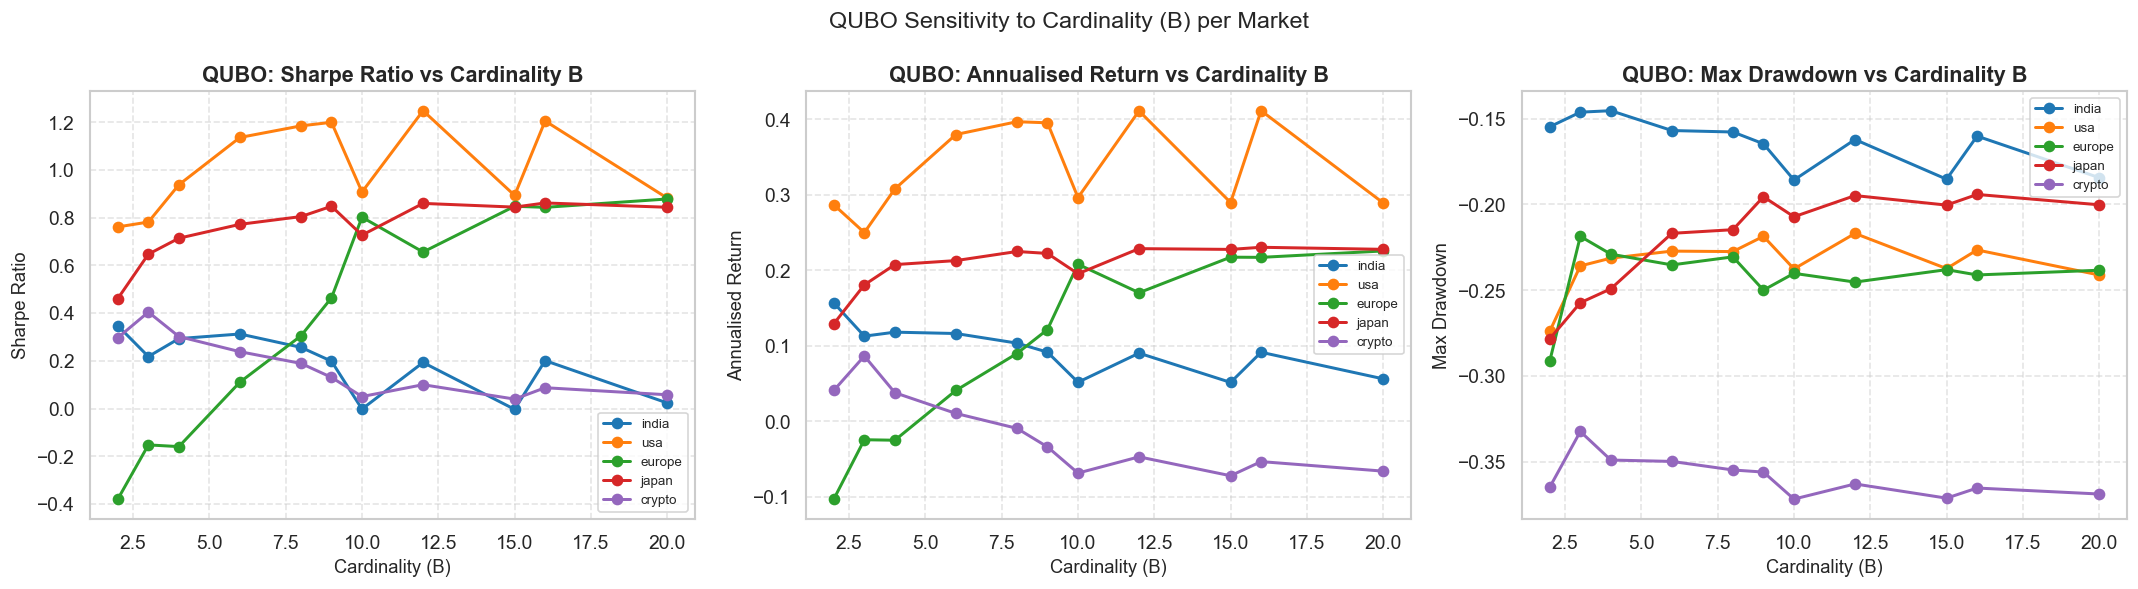

In [14]:
qubo_df = df[df["strategy"] == "QUBO"].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ["sharpe_ratio", "ann_return", "max_drawdown"]
titles  = ["Sharpe Ratio", "Annualised Return", "Max Drawdown"]

for ax, metric, title in zip(axes, metrics, titles):
    for mkt, color in zip(MARKETS, MPALETTE):
        sub = qubo_df[qubo_df["market"] == mkt]
        grp = sub.groupby("B")[metric].mean()
        ax.plot(grp.index, grp.values, marker="o", label=mkt, color=color, linewidth=1.8)
    ax.set_xlabel("Cardinality (B)"); ax.set_ylabel(title)
    ax.set_title(f"QUBO: {title} vs Cardinality B")
    ax.legend(fontsize=8); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("QUBO Sensitivity to Cardinality (B) per Market", fontsize=14)
plt.tight_layout()
plt.show()

### 7.2  Correlation Penalty (q)

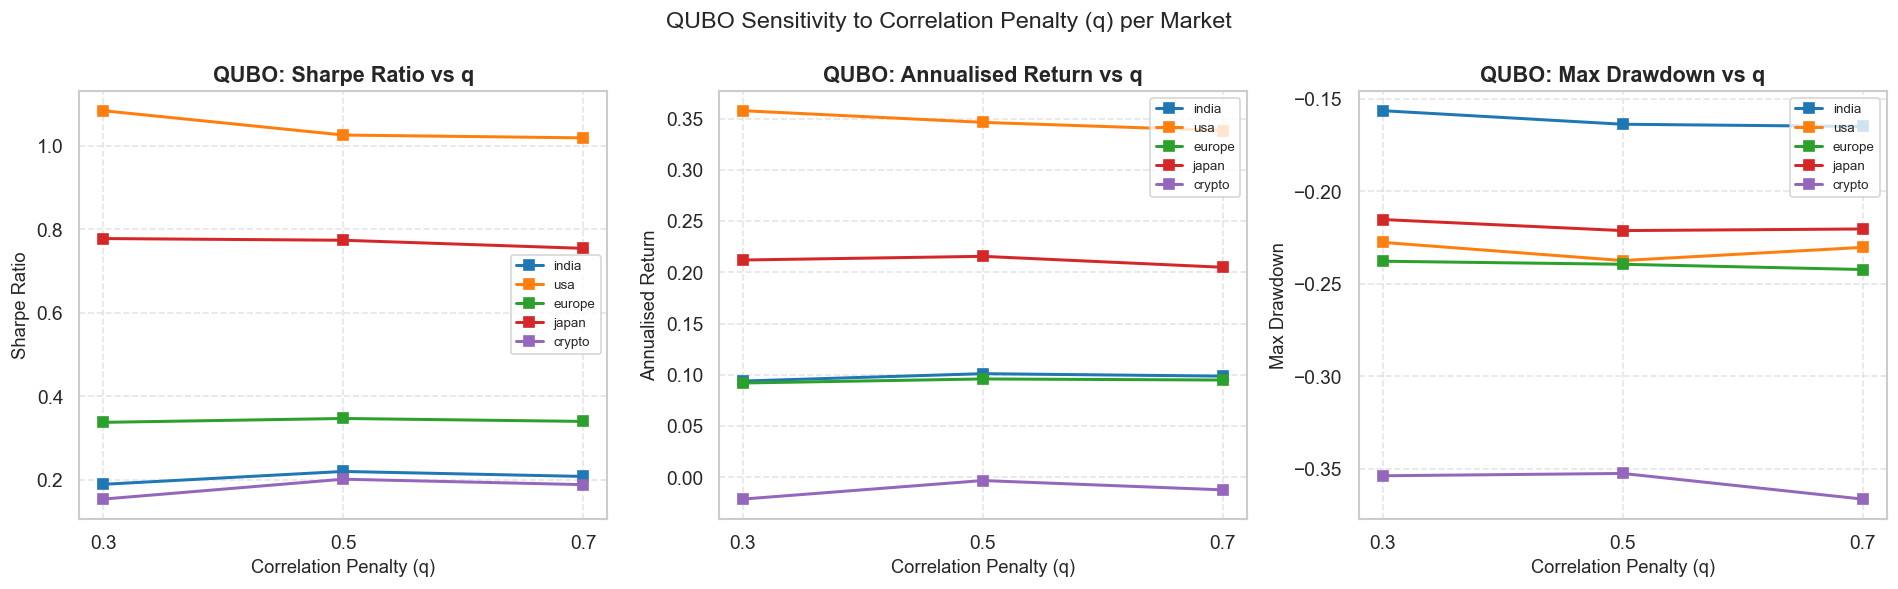

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, title in zip(axes, metrics, titles):
    grp = qubo_df.groupby(["q","market"])[metric].mean().unstack("market")[MARKETS]
    for mkt, color in zip(MARKETS, MPALETTE):
        ax.plot(grp.index, grp[mkt].values, marker="s",
                label=mkt, color=color, linewidth=1.8)
    ax.set_xlabel("Correlation Penalty (q)"); ax.set_ylabel(title)
    ax.set_title(f"QUBO: {title} vs q")
    ax.legend(fontsize=8); ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_xticks([0.3, 0.5, 0.7])

fig.suptitle("QUBO Sensitivity to Correlation Penalty (q) per Market", fontsize=14)
plt.tight_layout()
plt.show()

### 7.3  Lookback Window

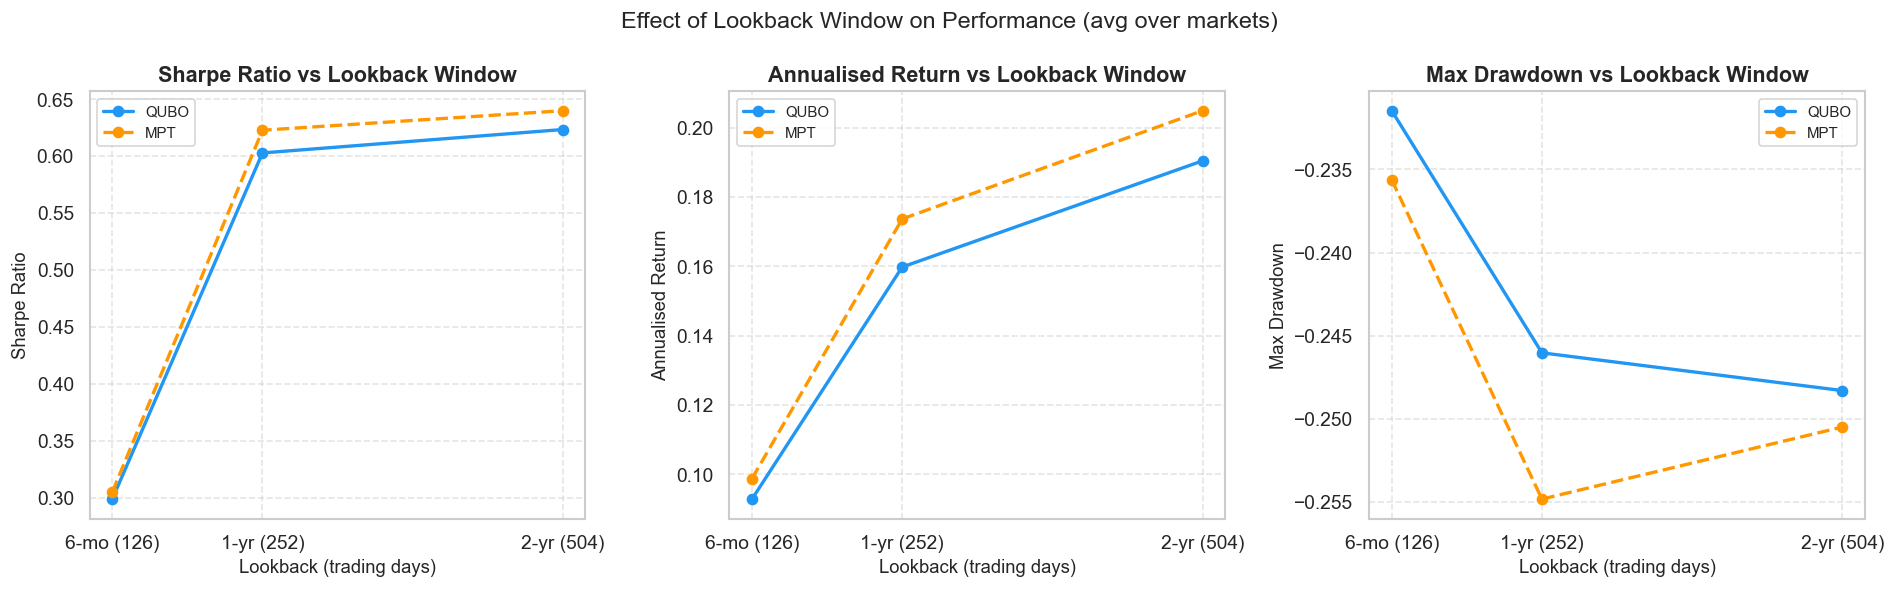

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, title in zip(axes, metrics, titles):
    for strat, linestyle in zip(strat_order, ["-", "--", "-."]):
        grp = df[df["strategy"]==strat].groupby(["lookback","market"])[metric].mean().unstack("market")
        mean_across_markets = grp.mean(axis=1)
        ax.plot(mean_across_markets.index, mean_across_markets.values,
                marker="o", linestyle=linestyle, label=strat,
                color=PALETTE[strat], linewidth=2)
    ax.set_xlabel("Lookback (trading days)"); ax.set_ylabel(title)
    ax.set_title(f"{title} vs Lookback Window")
    ax.set_xticks([126, 252, 504])
    ax.set_xticklabels(["6-mo (126)", "1-yr (252)", "2-yr (504)"])
    ax.legend(fontsize=9); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Effect of Lookback Window on Performance (avg over markets)", fontsize=14)
plt.tight_layout()
plt.show()

### 7.4  Sharpe Sensitivity Heat-map: B × q (QUBO per market)

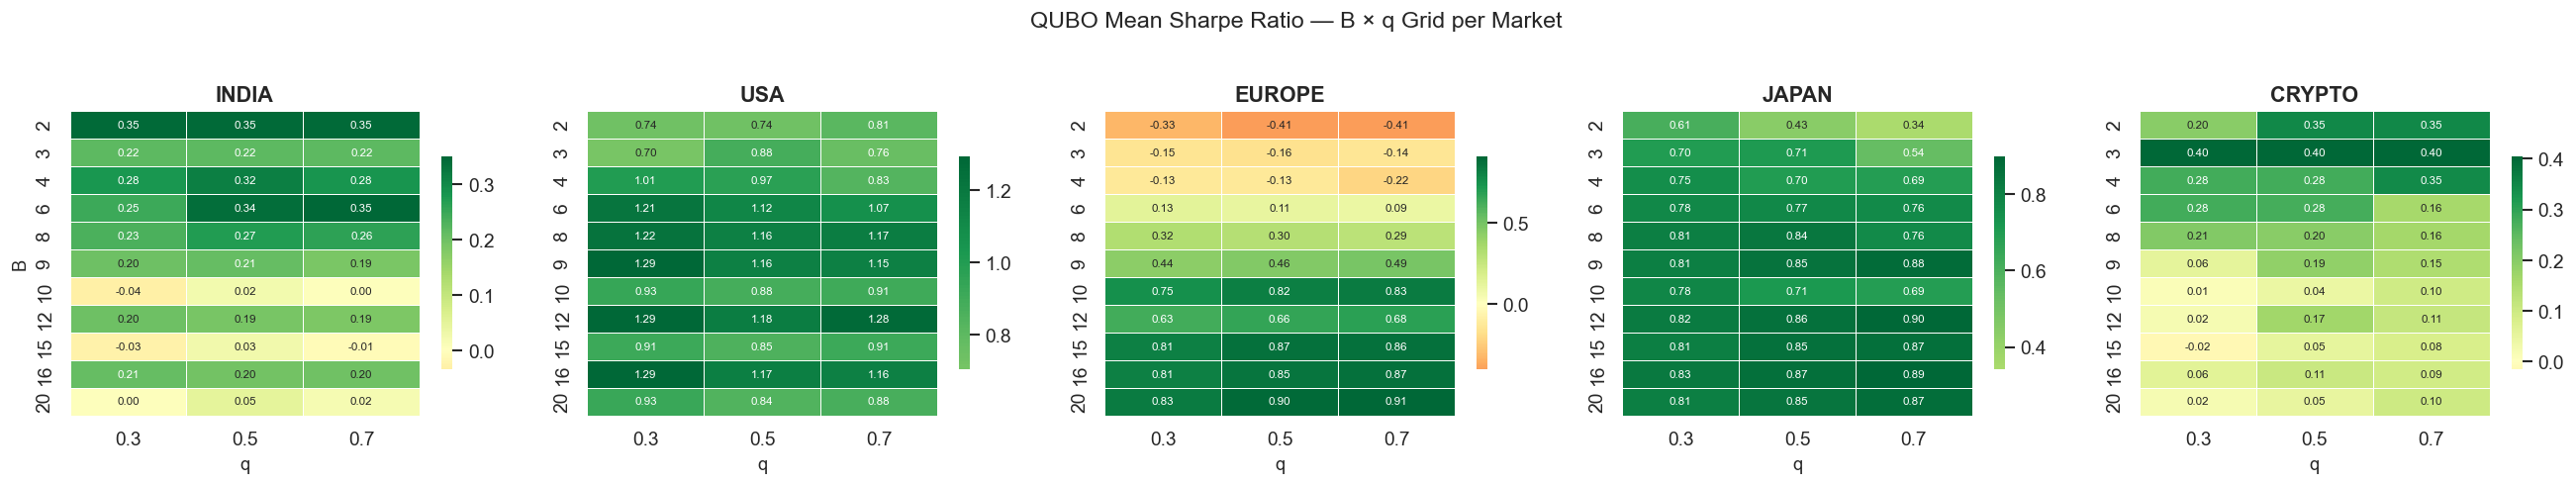

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, market in zip(axes, MARKETS):
    sub   = qubo_df[qubo_df["market"] == market]
    pivot = sub.groupby(["B","q"])["sharpe_ratio"].mean().unstack("q")
    sns.heatmap(pivot, ax=ax, annot=True, fmt=".2f",
                cmap="RdYlGn", center=0, linewidths=0.3,
                cbar_kws={"shrink": 0.7}, annot_kws={"size": 7})
    ax.set_title(market.upper())
    ax.set_xlabel("q"); ax.set_ylabel("B" if ax == axes[0] else "")

fig.suptitle("QUBO Mean Sharpe Ratio — B × q Grid per Market", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 8  Universe Size Scaling Analysis

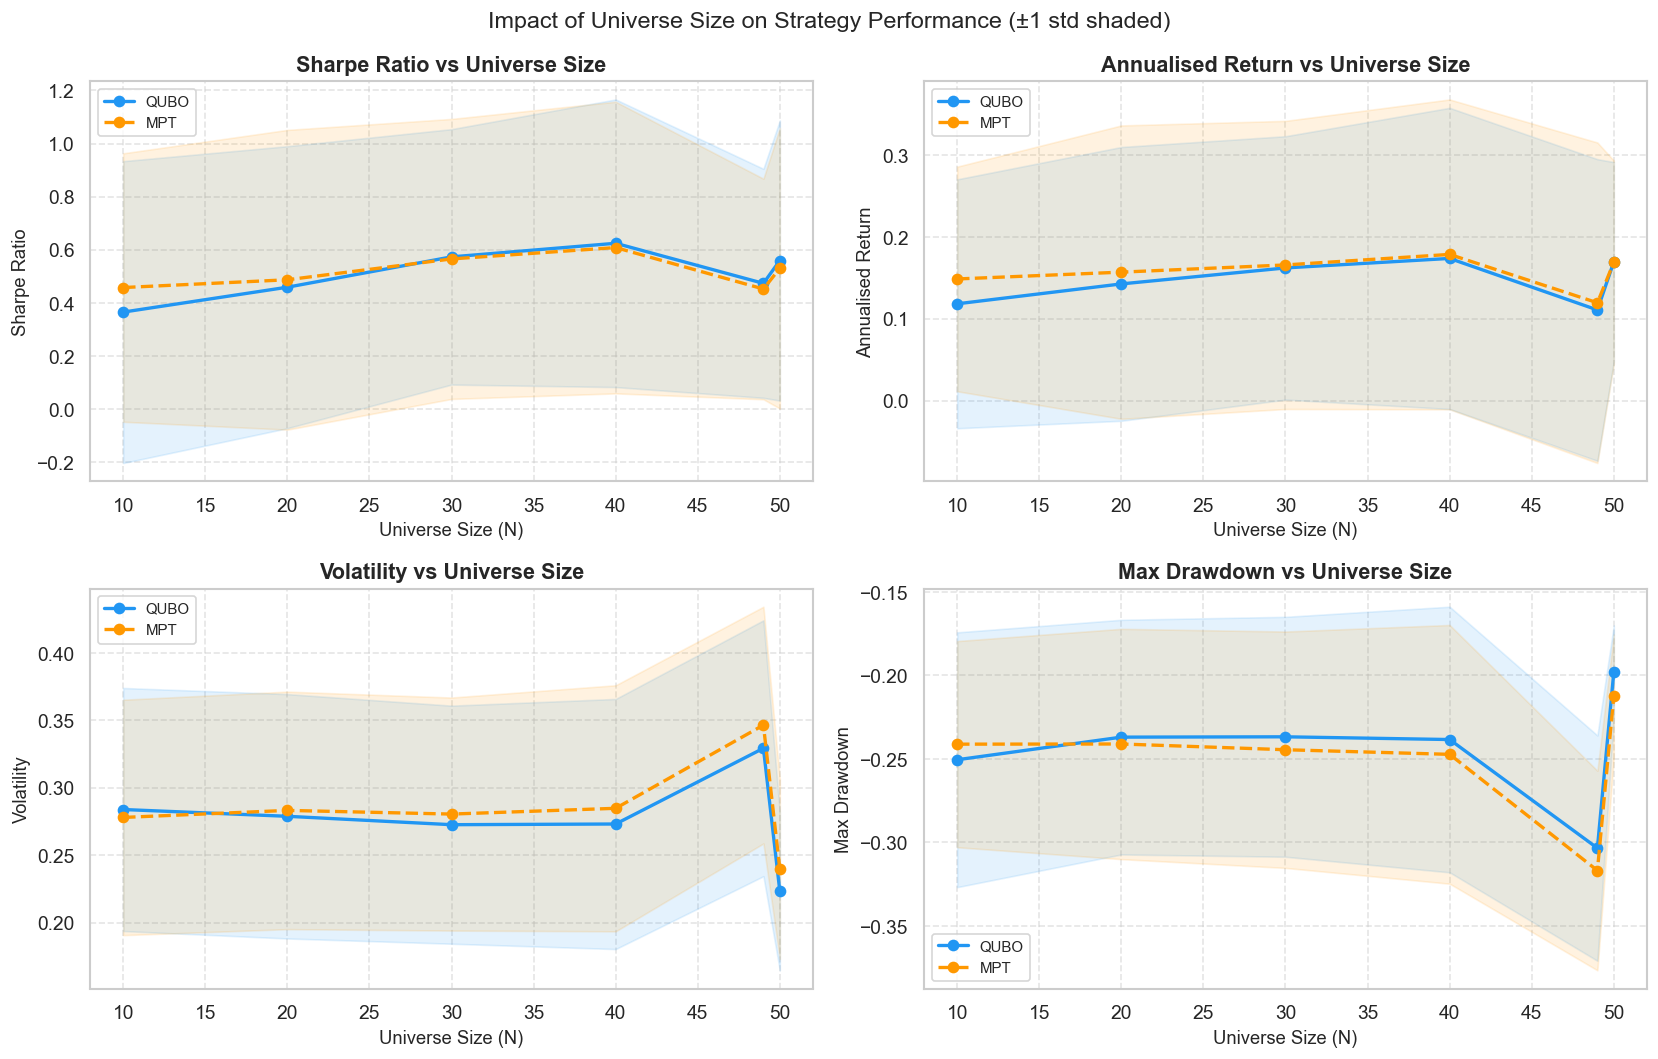

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
u_metrics = ["sharpe_ratio","ann_return","volatility","max_drawdown"]
u_titles  = ["Sharpe Ratio","Annualised Return","Volatility","Max Drawdown"]

for ax, metric, title in zip(axes.flatten(), u_metrics, u_titles):
    for strat, linestyle in zip(strat_order, ["-","--","-."]):
        sub = df[df["strategy"]==strat]
        grp = sub.groupby("universe_size")[metric].agg(["mean","std"])
        ax.plot(grp.index, grp["mean"], marker="o", linestyle=linestyle,
                color=PALETTE[strat], label=strat, linewidth=2)
        ax.fill_between(grp.index,
                        grp["mean"] - grp["std"],
                        grp["mean"] + grp["std"],
                        color=PALETTE[strat], alpha=0.12)
    ax.set_xlabel("Universe Size (N)"); ax.set_ylabel(title)
    ax.set_title(f"{title} vs Universe Size")
    ax.legend(fontsize=9); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Impact of Universe Size on Strategy Performance (±1 std shaded)", fontsize=14)
plt.tight_layout()
plt.show()

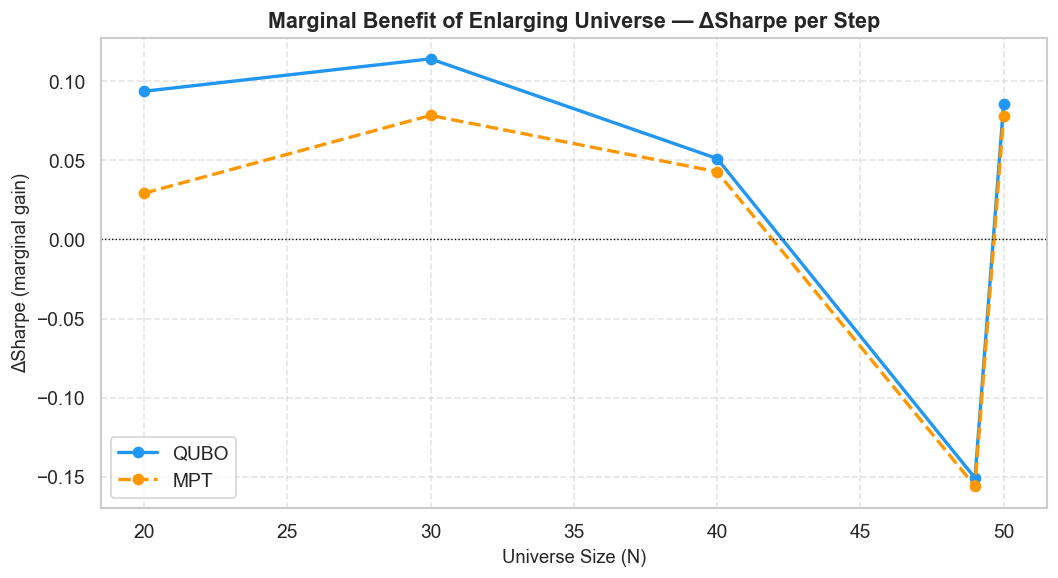

In [19]:
# Marginal gain in Sharpe as N grows
fig, ax = plt.subplots(figsize=(9, 5))

for strat, linestyle in zip(strat_order, ["-","--","-."]):
    sub  = df[df["strategy"]==strat].groupby("universe_size")["sharpe_ratio"].mean()
    delta = sub.diff()
    ax.plot(delta.index, delta.values, marker="o", linestyle=linestyle,
            color=PALETTE[strat], label=strat, linewidth=2)

ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_xlabel("Universe Size (N)"); ax.set_ylabel("ΔSharpe (marginal gain)")
ax.set_title("Marginal Benefit of Enlarging Universe — ΔSharpe per Step")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

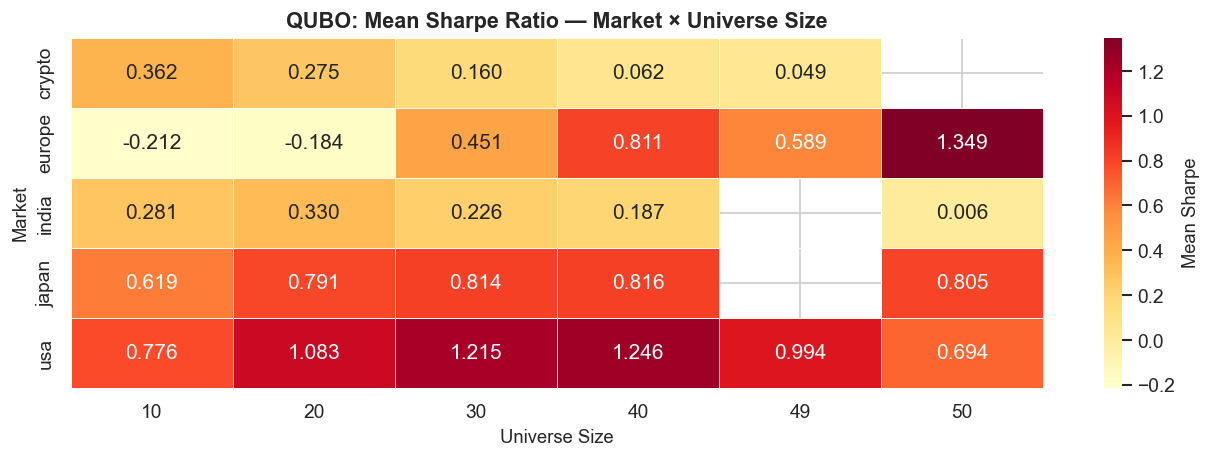

In [20]:
# Per-market universe-size heatmap for QUBO
pivot_u = (qubo_df.groupby(["market","universe_size"])["sharpe_ratio"]
           .mean().unstack("universe_size").round(3))
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(pivot_u, ax=ax, annot=True, fmt=".3f", cmap="YlOrRd",
            linewidths=0.4, cbar_kws={"label": "Mean Sharpe"})
ax.set_title("QUBO: Mean Sharpe Ratio — Market × Universe Size")
ax.set_xlabel("Universe Size"); ax.set_ylabel("Market")
plt.tight_layout()
plt.show()

## 9  QUBO Solver Diagnostics

Checks written inside `qubov2.ipynb` verify:
- **Check 1** — Objective scale ratio (λ calibration)
- **Check 2** — Mid-vs-high / mid-vs-low sensitivity overlap
- **Check 3** — Energy gap B vs B+1 (cardinality separation)

`diag_all_ok` is `True` only when all three checks pass.


In [21]:
# Overall pass rate
diag_counts = qubo_df["diag_all_ok"].value_counts()
print("QUBO diagnostic pass/fail counts:")
print(diag_counts)
print(f"\nPass rate: {diag_counts.get(True,0)/len(qubo_df)*100:.1f}%")

QUBO diagnostic pass/fail counts:
diag_all_ok
True     660
False     15
Name: count, dtype: int64

Pass rate: 97.8%


In [22]:
# Pass rate per market
pr = (qubo_df.groupby("market")["diag_all_ok"]
      .agg(["sum","count"])
      .rename(columns={"sum":"pass","count":"total"}))
pr["pass_rate_%"] = (pr["pass"]/pr["total"]*100).round(1)
print("Diagnostic pass rate per market:")
pr

Diagnostic pass rate per market:


,pass,total,pass_rate_%
market,,,
crypto,135,135,100.0000
europe,129,135,95.6000
india,126,135,93.3000
japan,135,135,100.0000
usa,135,135,100.0000


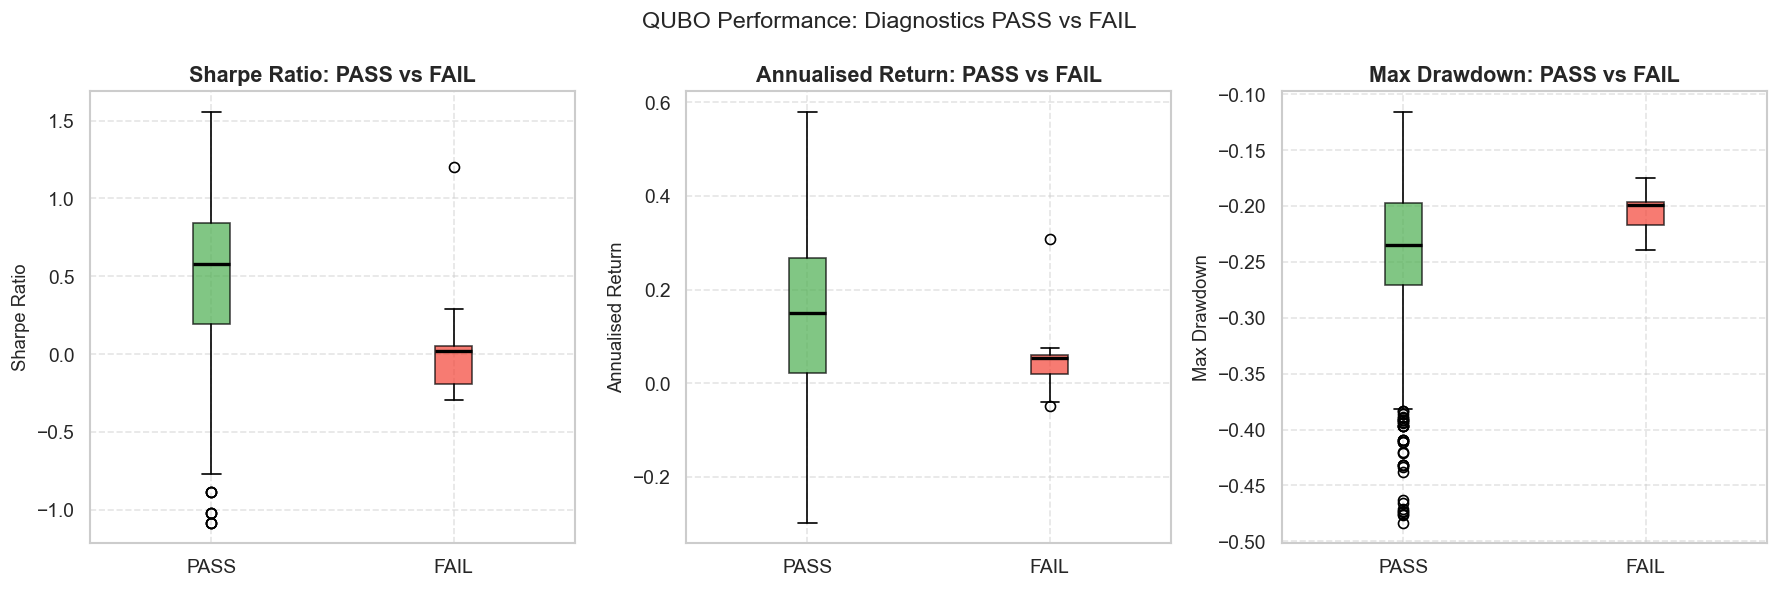

In [23]:
# Performance: PASS vs FAIL
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric, title in zip(axes, ["sharpe_ratio","ann_return","max_drawdown"],
                              ["Sharpe Ratio","Annualised Return","Max Drawdown"]):
    data_pass = qubo_df[qubo_df["diag_all_ok"]==True][metric].dropna()
    data_fail = qubo_df[qubo_df["diag_all_ok"]==False][metric].dropna()
    bp = ax.boxplot([data_pass, data_fail], patch_artist=True,
                    medianprops=dict(color="black", linewidth=2))
    bp["boxes"][0].set_facecolor("#4CAF50"); bp["boxes"][0].set_alpha(0.7)
    if len(bp["boxes"]) > 1:
        bp["boxes"][1].set_facecolor("#F44336"); bp["boxes"][1].set_alpha(0.7)
    ax.set_xticks([1,2]); ax.set_xticklabels(["PASS","FAIL"])
    ax.set_title(f"{title}: PASS vs FAIL"); ax.set_ylabel(title)
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("QUBO Performance: Diagnostics PASS vs FAIL", fontsize=14)
plt.tight_layout()
plt.show()

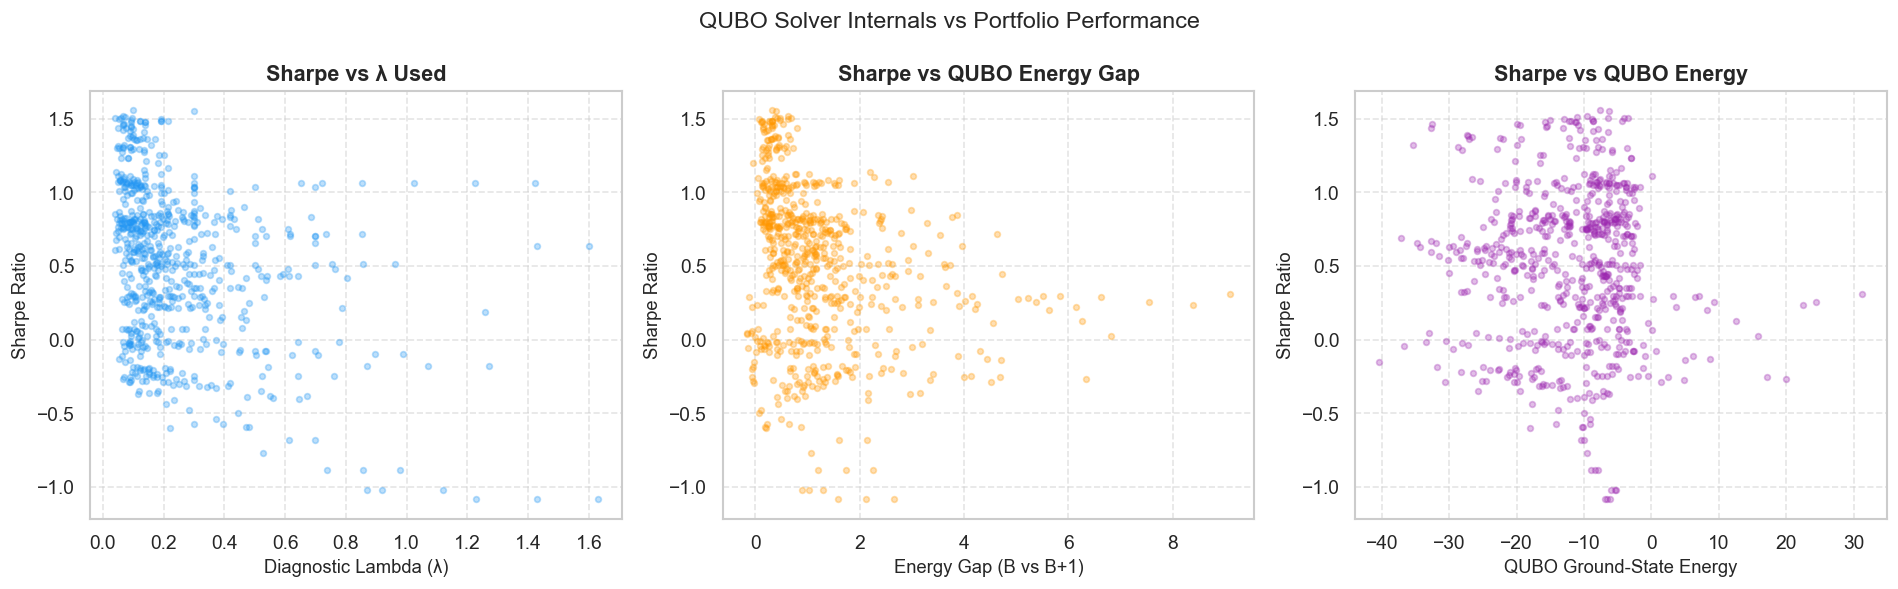

In [24]:
# Lambda calibration analysis
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
ax.scatter(qubo_df["diag_lambda"], qubo_df["sharpe_ratio"],
           alpha=0.3, s=12, color="#2196F3")
ax.set_xlabel("Diagnostic Lambda (λ)"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Sharpe vs λ Used")
ax.grid(True, linestyle="--", alpha=0.5)

ax = axes[1]
ax.scatter(qubo_df["diag_energy_gap"], qubo_df["sharpe_ratio"],
           alpha=0.3, s=12, color="#FF9800")
ax.set_xlabel("Energy Gap (B vs B+1)"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Sharpe vs QUBO Energy Gap")
ax.grid(True, linestyle="--", alpha=0.5)

ax = axes[2]
ax.scatter(qubo_df["qubo_energy"], qubo_df["sharpe_ratio"],
           alpha=0.3, s=12, color="#9C27B0")
ax.set_xlabel("QUBO Ground-State Energy"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Sharpe vs QUBO Energy")
ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("QUBO Solver Internals vs Portfolio Performance", fontsize=14)
plt.tight_layout()
plt.show()

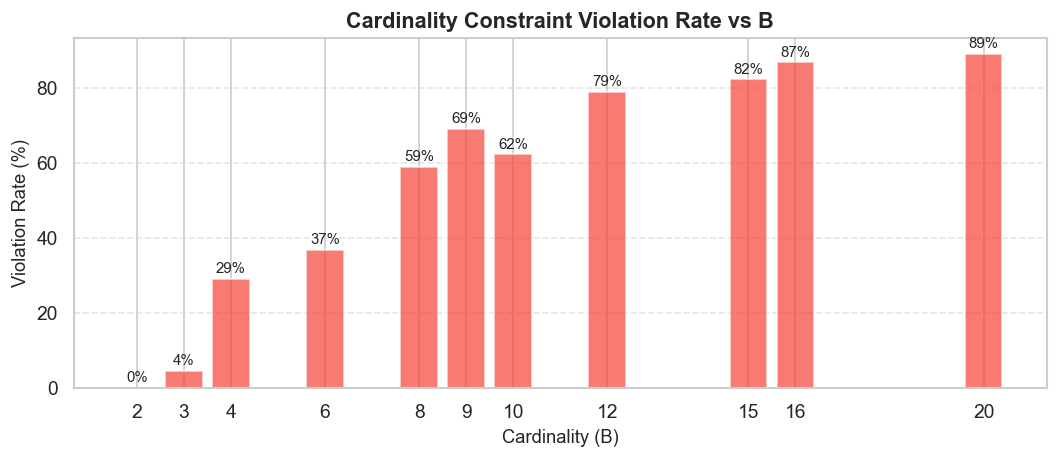

In [25]:
# Cardinality violation rate per B value
viol_rate = (qubo_df.groupby("B")["cardinality_violated"]
             .mean().mul(100).round(1))
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(viol_rate.index, viol_rate.values,
              color="#F44336", alpha=0.7, edgecolor="white")
ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
ax.set_xlabel("Cardinality (B)"); ax.set_ylabel("Violation Rate (%)")
ax.set_title("Cardinality Constraint Violation Rate vs B")
ax.set_xticks(viol_rate.index)
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 10  Portfolio Concentration Analysis

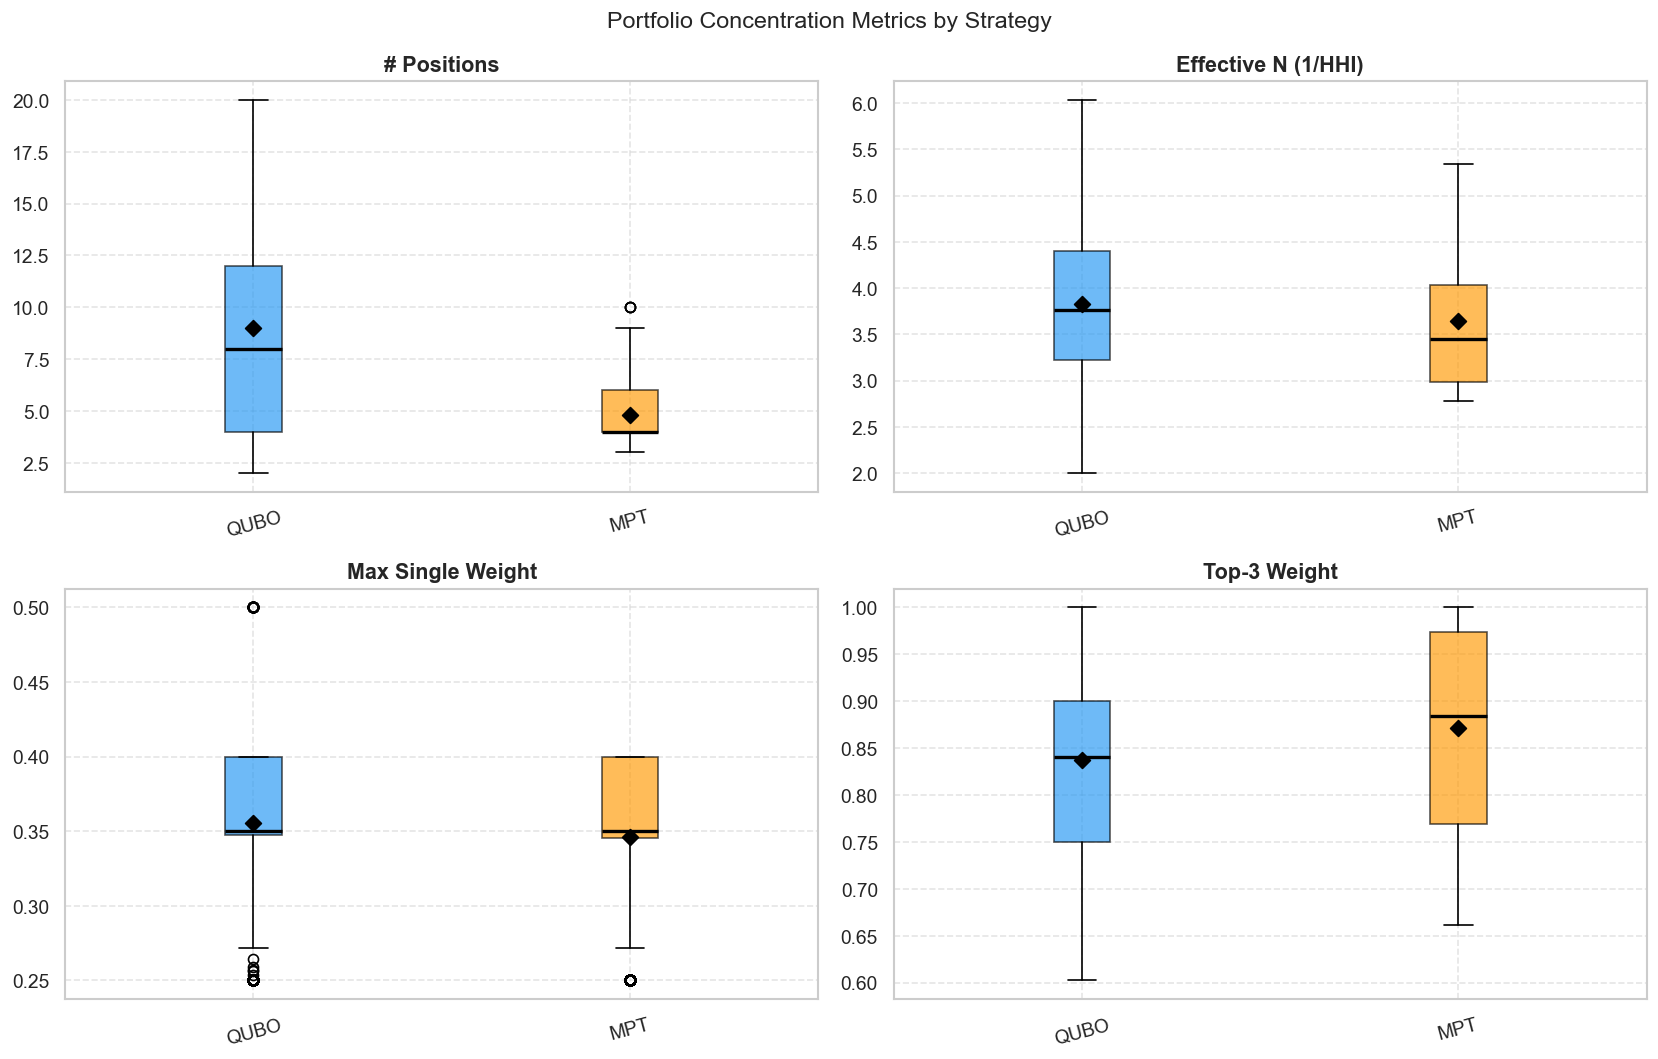

In [26]:
conc_metrics = ["conc_n_positions","conc_effective_n",
                "conc_max_weight","conc_top3_weight"]
conc_titles  = ["# Positions","Effective N (1/HHI)",
                "Max Single Weight","Top-3 Weight"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, metric, title in zip(axes.flatten(), conc_metrics, conc_titles):
    data   = [df[df["strategy"]==s][metric].dropna() for s in strat_order]
    colors = [PALETTE[s] for s in strat_order]
    bp = ax.boxplot(data, patch_artist=True, notch=False,
                    medianprops=dict(color="black", linewidth=2))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color); patch.set_alpha(0.65)
    means = [d.mean() for d in data]
    ax.scatter(range(1, len(strat_order)+1), means,
               color="black", marker="D", s=45, zorder=5)
    ax.set_xticks(range(1, len(strat_order)+1))
    ax.set_xticklabels(strat_order, rotation=15)
    ax.set_title(title); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Portfolio Concentration Metrics by Strategy", fontsize=14)
plt.tight_layout()
plt.show()

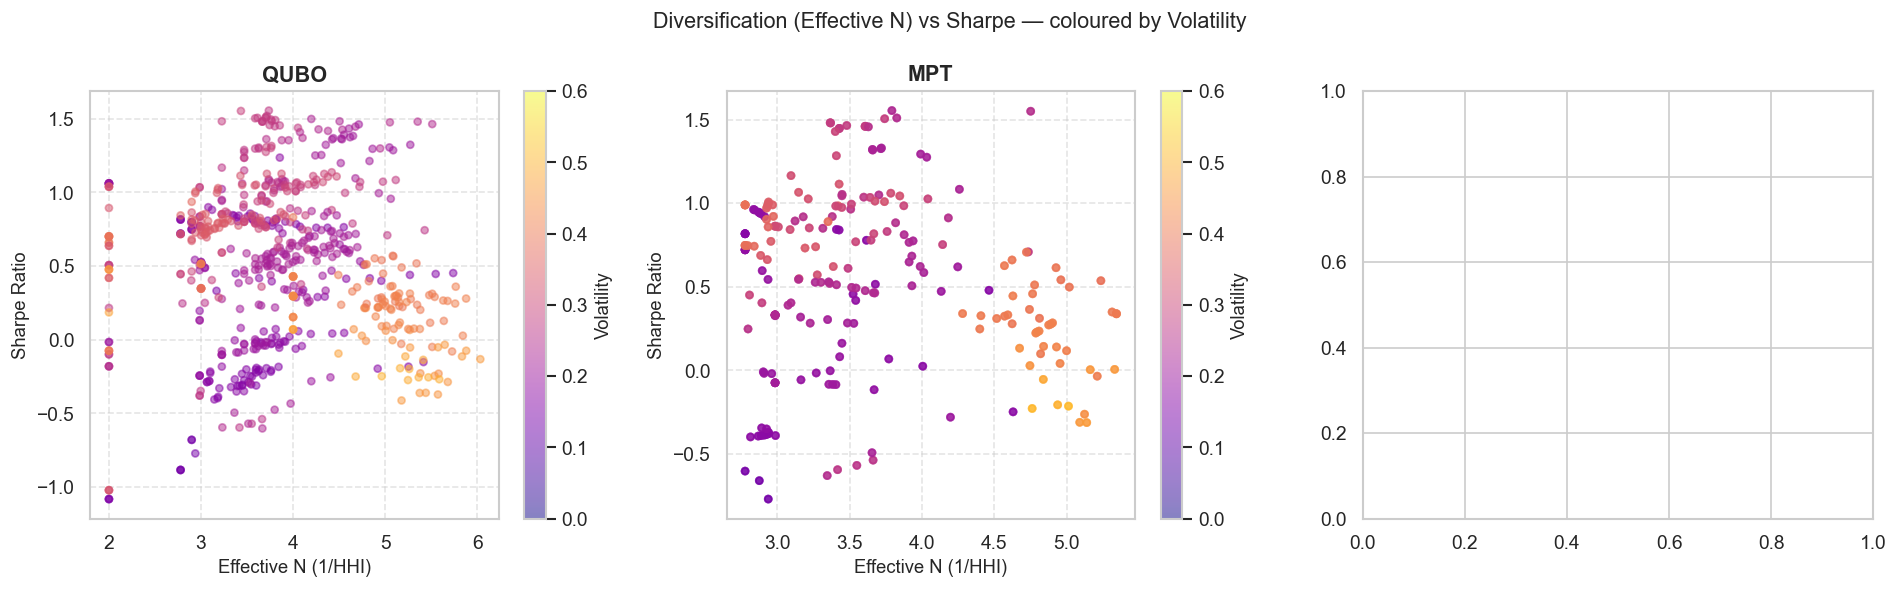

In [27]:
# Concentration vs performance scatter
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, strat in zip(axes, strat_order):
    sub = df[df["strategy"]==strat].dropna(subset=["conc_effective_n","sharpe_ratio"])
    sc  = ax.scatter(sub["conc_effective_n"], sub["sharpe_ratio"],
                     c=sub["volatility"], cmap="plasma",
                     alpha=0.5, s=18, vmin=0, vmax=0.6)
    plt.colorbar(sc, ax=ax, label="Volatility")
    ax.set_xlabel("Effective N (1/HHI)")
    ax.set_ylabel("Sharpe Ratio")
    ax.set_title(strat)
    ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Diversification (Effective N) vs Sharpe — coloured by Volatility", fontsize=13)
plt.tight_layout()
plt.show()

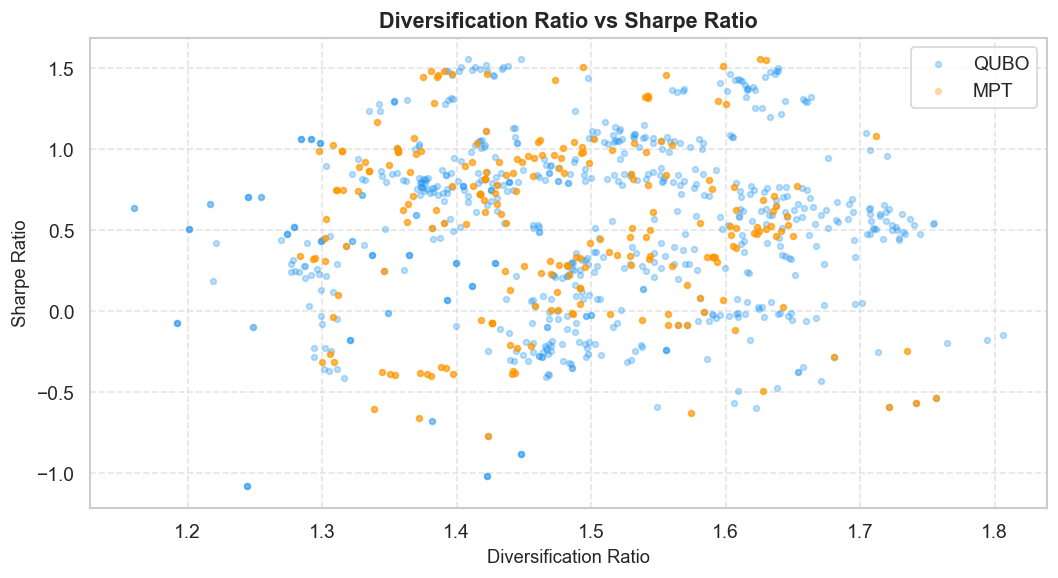

In [28]:
# Diversification ratio vs Sharpe per strategy
fig, ax = plt.subplots(figsize=(9, 5))
for strat in strat_order:
    sub = df[df["strategy"]==strat].dropna(subset=["diversification_ratio","sharpe_ratio"])
    ax.scatter(sub["diversification_ratio"], sub["sharpe_ratio"],
               color=PALETTE[strat], alpha=0.3, s=12, label=strat)

ax.set_xlabel("Diversification Ratio"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Diversification Ratio vs Sharpe Ratio")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 11  Inter-Metric Correlation Analysis

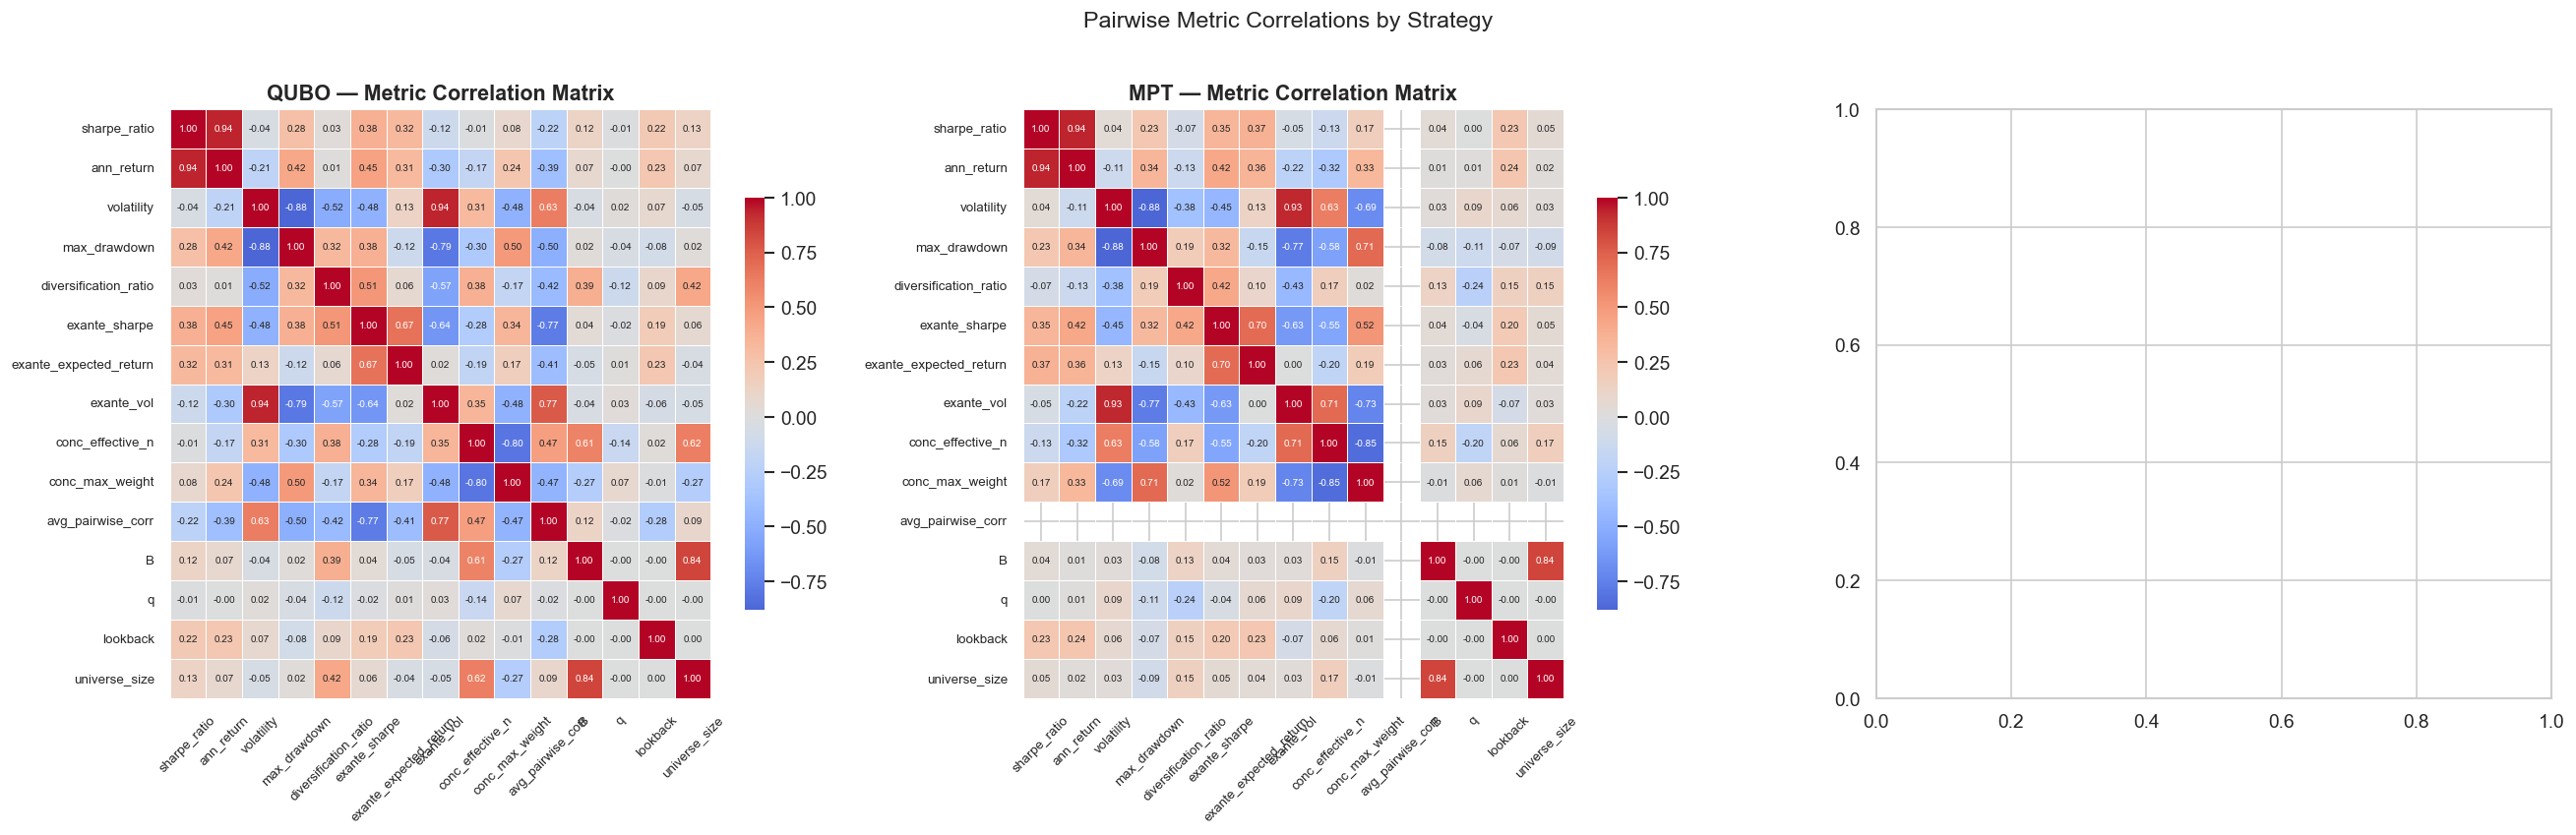

In [29]:
corr_cols = ["sharpe_ratio","ann_return","volatility","max_drawdown",
             "diversification_ratio","exante_sharpe","exante_expected_return",
             "exante_vol","conc_effective_n","conc_max_weight",
             "avg_pairwise_corr","B","q","lookback","universe_size"]

fig, axes = plt.subplots(1, 3, figsize=(22, 7))

for ax, strat in zip(axes, strat_order):
    sub  = df[df["strategy"]==strat][corr_cols].dropna(how="all")
    corr = sub.corr().round(2)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, ax=ax, mask=False, annot=True, fmt=".2f",
                cmap="coolwarm", center=0, linewidths=0.3,
                annot_kws={"size": 6}, cbar_kws={"shrink": 0.7})
    ax.set_title(f"{strat} — Metric Correlation Matrix")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0,  labelsize=8)

fig.suptitle("Pairwise Metric Correlations by Strategy", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

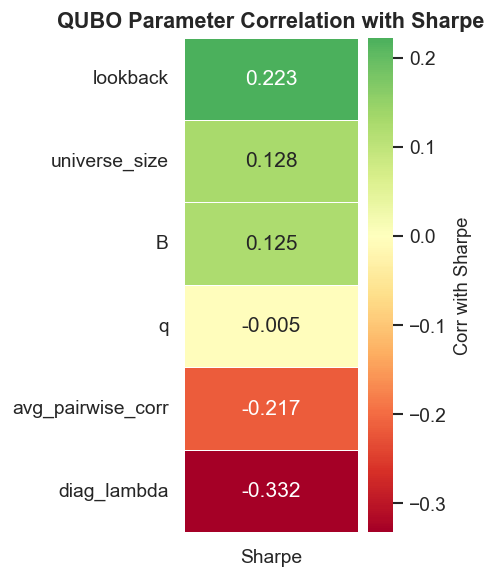

In [30]:
# Parameter impact heatmap (avg Sharpe) - QUBO only
param_cols = ["B", "q", "lookback", "universe_size",
              "avg_pairwise_corr", "diag_lambda"]
perf_col   = "sharpe_ratio"

sub  = qubo_df[param_cols + [perf_col]].dropna()
corr = sub.corr()[[perf_col]].drop(perf_col).sort_values(perf_col, ascending=False)

fig, ax = plt.subplots(figsize=(4, 5))
sns.heatmap(corr, ax=ax, annot=True, fmt=".3f", cmap="RdYlGn",
            center=0, linewidths=0.5, cbar_kws={"label": "Corr with Sharpe"})
ax.set_title("QUBO Parameter Correlation with Sharpe")
ax.set_ylabel(""); ax.set_xticklabels(["Sharpe"])
plt.tight_layout()
plt.show()

## 17  General Pareto Frontier (All Markets)

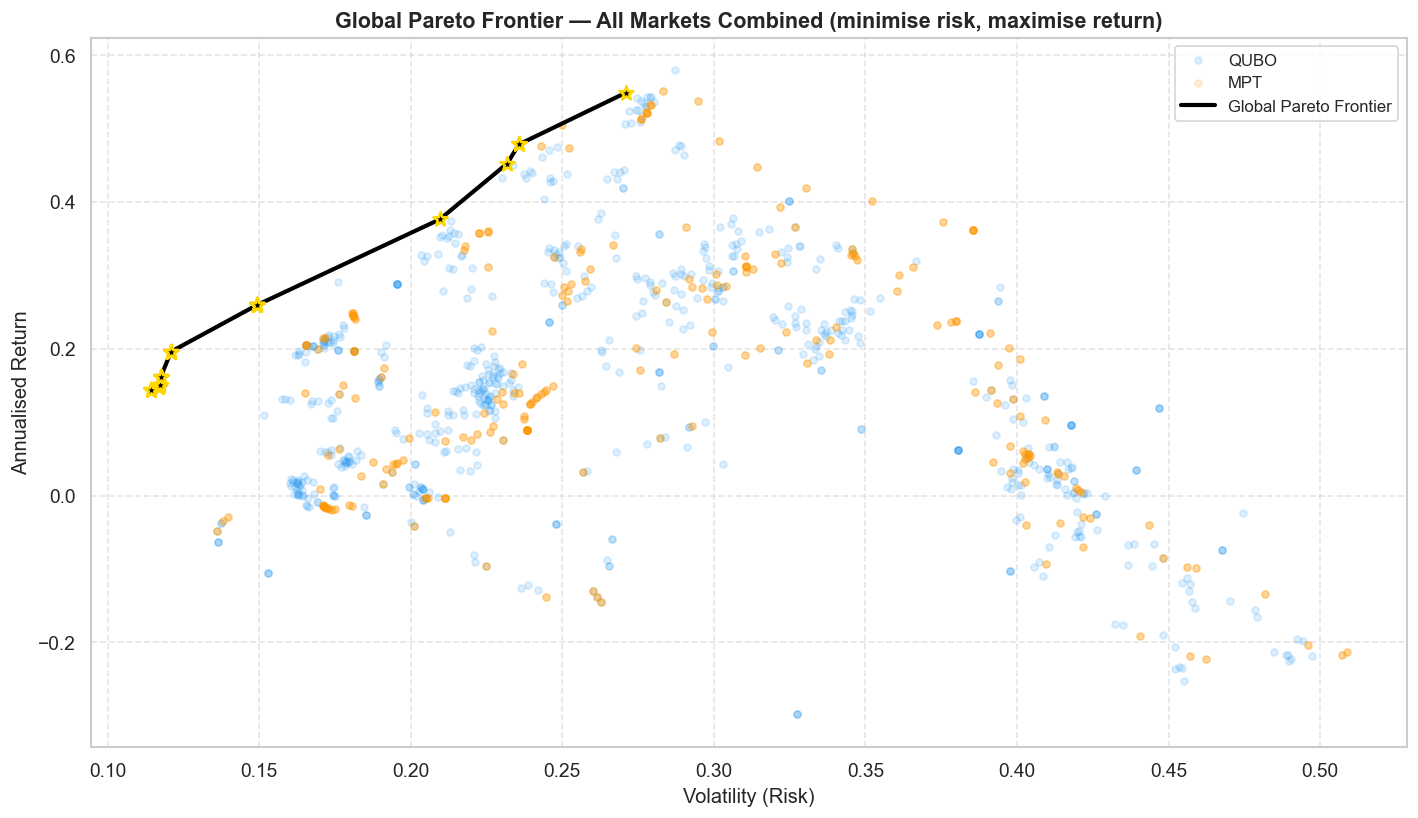

Global Pareto frontier contains 69 points

Frontier points:
      market strategy  volatility  sharpe_ratio  ann_return   B      q  lookback
179    india      NaN      0.1144        0.6642      0.1439   6 0.5000       504
188    india      NaN      0.1144        0.6642      0.1439   6 0.7000       504
170    india      NaN      0.1144        0.6642      0.1439   6 0.3000       504
242    india      NaN      0.1144        0.6642      0.1439  12 0.7000       504
215    india      NaN      0.1144        0.6642      0.1439   9 0.7000       504
224    india      NaN      0.1144        0.6642      0.1439  12 0.3000       504
206    india      NaN      0.1144        0.6642      0.1439   9 0.5000       504
197    india      NaN      0.1144        0.6642      0.1439   9 0.3000       504
233    india      NaN      0.1144        0.6642      0.1439  12 0.5000       504
251    india      NaN      0.1171        0.6796      0.1477   8 0.3000       504
260    india      NaN      0.1171        0.6796  

In [31]:
def get_global_pareto_frontier(df_in, x_col="volatility", y_col="sharpe_ratio"):
    """
    Compute the Pareto frontier across all markets combined.
    Minimise x_col (volatility), maximise y_col (Sharpe ratio).
    Returns the rows on the frontier, sorted by x_col.
    """
    pts = df_in[[x_col, y_col]].dropna().values
    idx = df_in[[x_col, y_col]].dropna().index
    pareto_idx = []
    
    for i, (xi, yi) in enumerate(pts):
        # A point is non-dominated if no other point is better or equal on both dimensions
        dominated = any(
            (pts[j, 0] <= xi) and (pts[j, 1] >= yi) and
            ((pts[j, 0] < xi) or (pts[j, 1] > yi))
            for j in range(len(pts)) if j != i
        )
        if not dominated:
            pareto_idx.append(idx[i])
    
    return df_in.loc[pareto_idx].sort_values(x_col)

# Filter outliers for cleaner plot
plot_df_global = df[(df["volatility"] < 1.5) & (df["ann_return"].abs() < 1.0)].copy()

# Compute global Pareto frontier
pf_global = get_global_pareto_frontier(plot_df_global)

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

# Scatter all points, colored by strategy
for strat in strat_order:
    sub = plot_df_global[plot_df_global["strategy"] == strat]
    ax.scatter(sub["volatility"], sub["ann_return"],
               color=PALETTE[strat], alpha=0.15, s=18, label=strat)

# Plot and highlight Pareto frontier
ax.plot(pf_global["volatility"], pf_global["ann_return"],
        color="black", linewidth=2.5, zorder=5, label="Global Pareto Frontier")
ax.scatter(pf_global["volatility"], pf_global["ann_return"],
           color="black", s=80, zorder=6, marker="*", edgecolor="gold", linewidth=1.5)

ax.set_xlabel("Volatility (Risk)", fontsize=12)
ax.set_ylabel("Annualised Return", fontsize=12)
ax.set_title("Global Pareto Frontier — All Markets Combined (minimise risk, maximise return)", fontsize=13, fontweight="bold")
ax.legend(fontsize=10, loc="best")
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Global Pareto frontier contains {len(pf_global)} points")
print("\nFrontier points:")
print(pf_global[["market", "strategy", "volatility", "sharpe_ratio", "ann_return", "B", "q", "lookback"]].to_string())

## 18  Best Parameters Sorted by Sharpe Ratio

Top 20 Best Configurations by Sharpe Ratio:


Summary of Top 20 Configurations:
  Average Sharpe:           1.5254
  Average Return:           0.5157
  Average Volatility:       0.2606
  Average Max Drawdown:     -0.2072
  Average Diversif. Ratio:  1.5325


Dominant Parameters in Top 20:
  QUBO wins:                8/20
  MPT wins:                 12/20
  Most common B:            12
  Most common q:            0.3
  Most common lookback:     252
  Most common universe_sz:  30


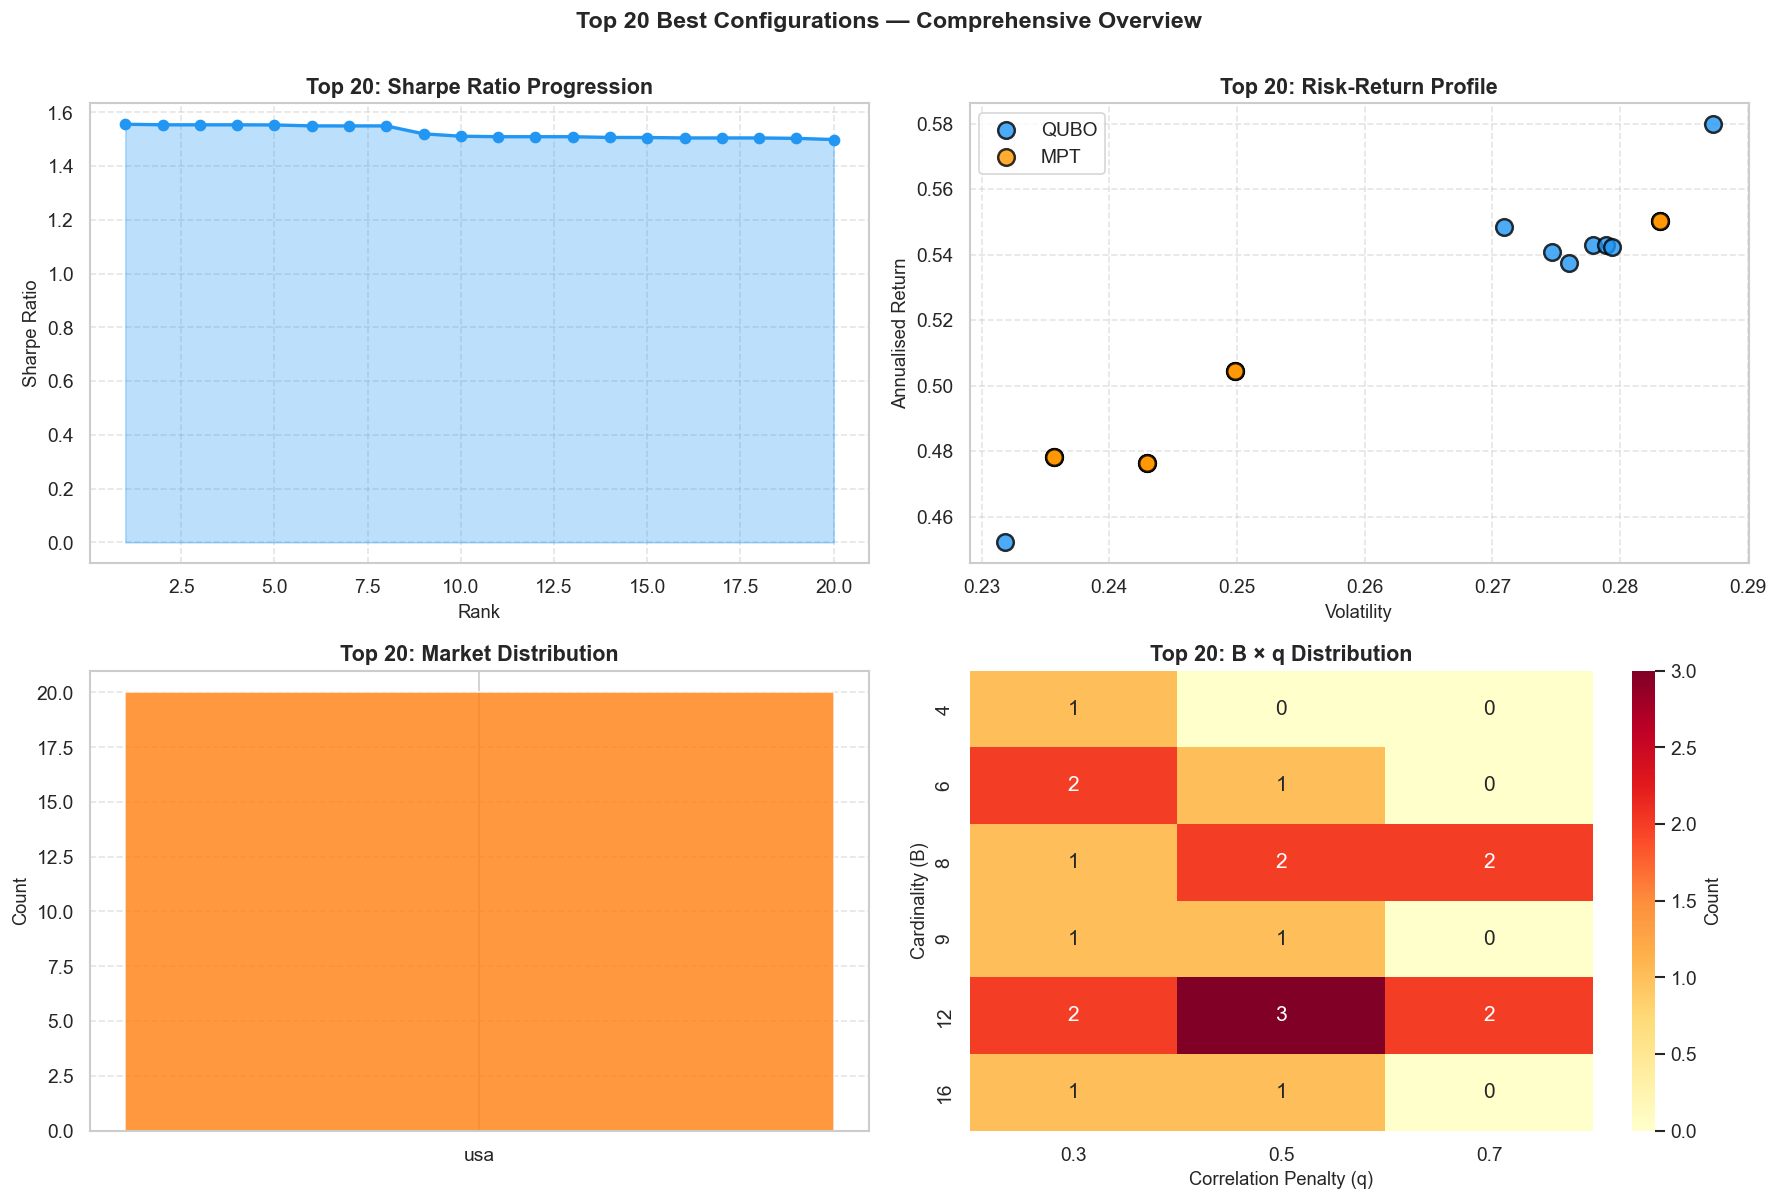

In [32]:
# Find best configurations by Sharpe ratio globally
best_by_sharpe = (df.dropna(subset=["sharpe_ratio"])
                   .sort_values("sharpe_ratio", ascending=False)
                   .head(20)
                   [["market", "strategy", "sharpe_ratio", "ann_return", "volatility", 
                     "max_drawdown", "diversification_ratio", "B", "q", "lookback", 
                     "universe_size", "lambda_used"]]
                   .reset_index(drop=True))

print("Top 20 Best Configurations by Sharpe Ratio:")
print("=" * 140)
best_by_sharpe

# Summary statistics
print("\n\nSummary of Top 20 Configurations:")
print(f"  Average Sharpe:           {best_by_sharpe['sharpe_ratio'].mean():.4f}")
print(f"  Average Return:           {best_by_sharpe['ann_return'].mean():.4f}")
print(f"  Average Volatility:       {best_by_sharpe['volatility'].mean():.4f}")
print(f"  Average Max Drawdown:     {best_by_sharpe['max_drawdown'].mean():.4f}")
print(f"  Average Diversif. Ratio:  {best_by_sharpe['diversification_ratio'].mean():.4f}")

# Dominant parameters in best configs
print("\n\nDominant Parameters in Top 20:")
print(f"  QUBO wins:                {(best_by_sharpe['strategy']=='QUBO').sum()}/20")
print(f"  MPT wins:                 {(best_by_sharpe['strategy']=='MPT').sum()}/20")
print(f"  Most common B:            {best_by_sharpe['B'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")
print(f"  Most common q:            {best_by_sharpe['q'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")
print(f"  Most common lookback:     {best_by_sharpe['lookback'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")
print(f"  Most common universe_sz:  {best_by_sharpe['universe_size'].mode()[0] if len(best_by_sharpe) > 0 else 'N/A'}")

# Visualize top 20
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Sharpe progression
ax = axes[0, 0]
ax.plot(range(1, 21), best_by_sharpe['sharpe_ratio'].values, marker='o', linewidth=2, markersize=6, color="#2196F3")
ax.fill_between(range(1, 21), best_by_sharpe['sharpe_ratio'].values, alpha=0.3, color="#2196F3")
ax.set_xlabel("Rank"); ax.set_ylabel("Sharpe Ratio")
ax.set_title("Top 20: Sharpe Ratio Progression")
ax.grid(True, linestyle='--', alpha=0.5)

# Return vs Volatility scatter
ax = axes[0, 1]
for strat in strat_order:
    sub = best_by_sharpe[best_by_sharpe['strategy'] == strat]
    ax.scatter(sub['volatility'], sub['ann_return'], label=strat,
               color=PALETTE[strat], s=100, edgecolor='black', linewidth=1.5, alpha=0.8)
ax.set_xlabel("Volatility"); ax.set_ylabel("Annualised Return")
ax.set_title("Top 20: Risk-Return Profile")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)

# Market distribution
ax = axes[1, 0]
mkt_counts = best_by_sharpe['market'].value_counts()
colors_mkt = [MPALETTE[MARKETS.index(m)] for m in mkt_counts.index]
ax.bar(mkt_counts.index, mkt_counts.values, color=colors_mkt, edgecolor='white', alpha=0.8)
ax.set_ylabel("Count")
ax.set_title("Top 20: Market Distribution")
ax.grid(True, axis='y', linestyle='--', alpha=0.5)

# Parameter heatmap (B vs q)
ax = axes[1, 1]
param_dist = best_by_sharpe.groupby(['B', 'q']).size().unstack(fill_value=0)
sns.heatmap(param_dist, ax=ax, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Count'})
ax.set_title("Top 20: B × q Distribution")
ax.set_xlabel("Correlation Penalty (q)")
ax.set_ylabel("Cardinality (B)")

fig.suptitle("Top 20 Best Configurations — Comprehensive Overview", fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

## 19  Average Sharpe Ratio vs Universe Size by Market

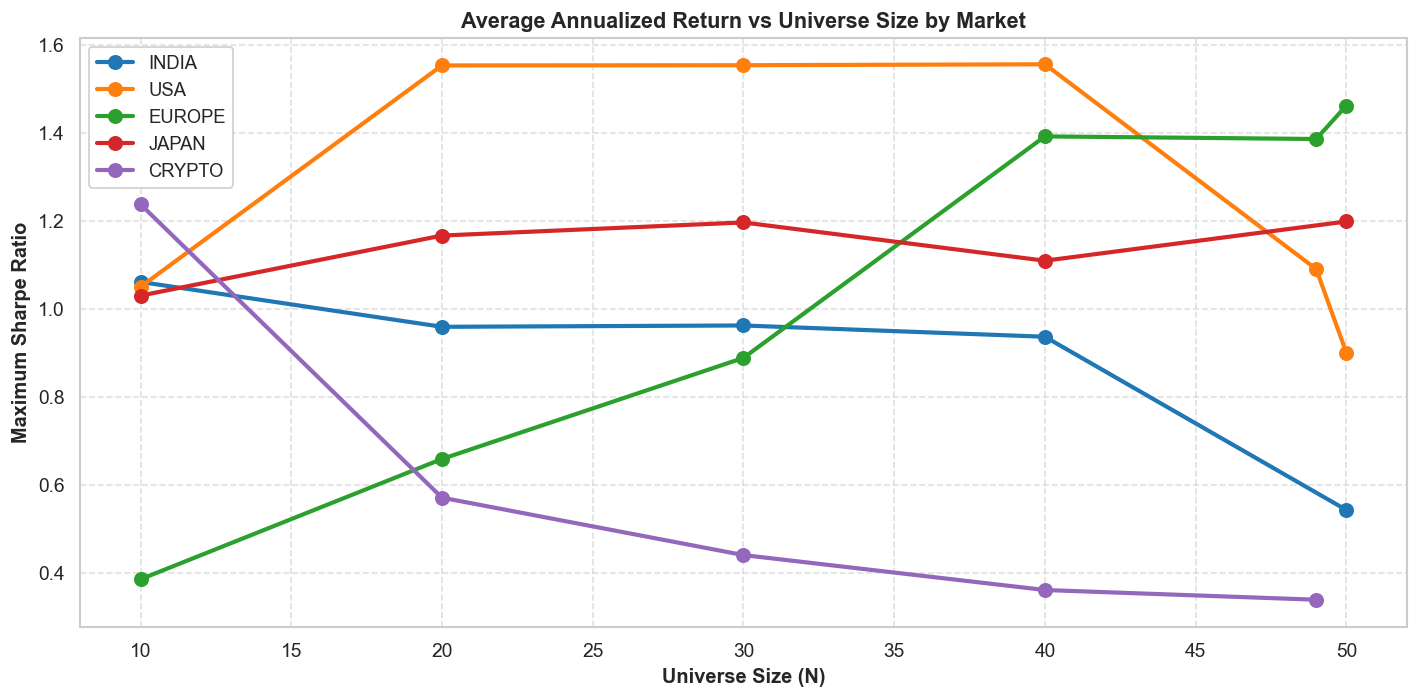

In [33]:
fig, ax = plt.subplots(figsize=(12, 6))

for i, market in enumerate(MARKETS):
    sub = df[df["market"] == market]
    grp = sub.groupby("universe_size")["sharpe_ratio"].max()
    ax.plot(grp.index, grp.values, marker="o", linewidth=2.5, markersize=8,
            label=market.upper(), color=MPALETTE[i])

ax.set_xlabel("Universe Size (N)", fontsize=12, fontweight="bold")
ax.set_ylabel("Maximum Sharpe Ratio", fontsize=12, fontweight="bold")
ax.set_title("Average Annualized Return vs Universe Size by Market", fontsize=13, fontweight="bold")
ax.legend(fontsize=11, loc="best", framealpha=0.95)

ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 12  Best Configurations per Market & Strategy

## 20  Sharpe Ratio vs Cardinality (B) — Optimal Number of Stocks

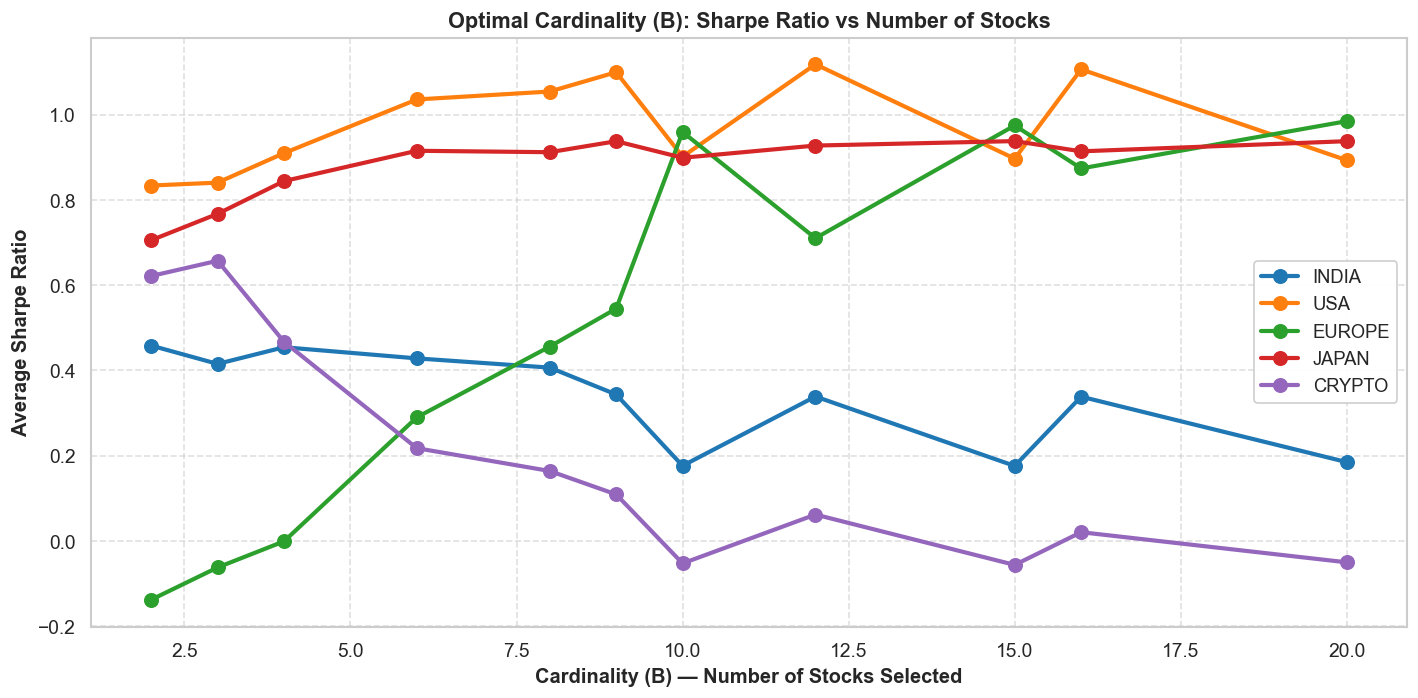


Optimal B per market (highest average Sharpe):
  INDIA        → B = 2   (avg Sharpe = 0.4584)
  USA          → B = 12   (avg Sharpe = 1.1186)
  EUROPE       → B = 20   (avg Sharpe = 0.9851)
  JAPAN        → B = 15   (avg Sharpe = 0.9383)
  CRYPTO       → B = 3   (avg Sharpe = 0.6575)


In [34]:
fig, ax = plt.subplots(figsize=(12, 6))

for i, market in enumerate(MARKETS):
    sub = df[df["market"] == market]
    grp = sub.groupby("B")["sharpe_ratio"].mean()
    ax.plot(grp.index, grp.values, marker="o", linewidth=2.5, markersize=8,
            label=market.upper(), color=MPALETTE[i])

ax.set_xlabel("Cardinality (B) — Number of Stocks Selected", fontsize=12, fontweight="bold")
ax.set_ylabel("Average Sharpe Ratio", fontsize=12, fontweight="bold")
ax.set_title("Optimal Cardinality (B): Sharpe Ratio vs Number of Stocks", fontsize=13, fontweight="bold")
ax.legend(fontsize=11, loc="best", framealpha=0.95)
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Summary: optimal B per market
print("\nOptimal B per market (highest average Sharpe):")
print("=" * 60)
for market in MARKETS:
    sub = df[df["market"] == market]
    best_b = sub.groupby("B")["sharpe_ratio"].mean().idxmax()
    best_sharpe = sub.groupby("B")["sharpe_ratio"].mean().max()
    print(f"  {market.upper():12} → B = {best_b}   (avg Sharpe = {best_sharpe:.4f})")

## 21  3D Surface Plot: B × Lookback vs Sharpe (Parameter Interaction)

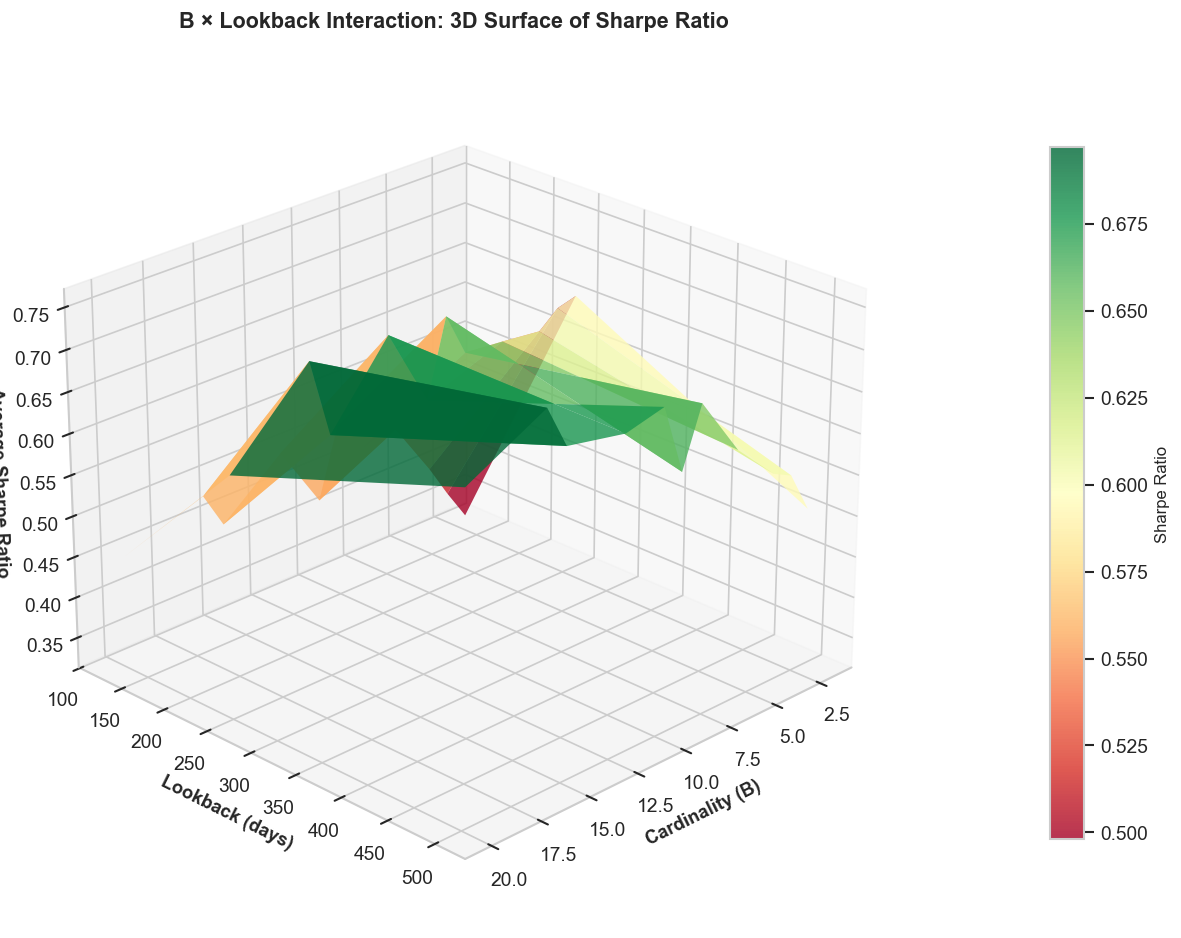


3D SURFACE ANALYSIS: B × Lookback Interaction

🔝 PEAK PERFORMANCE:
   B = 16, Lookback = 504 days → Sharpe = 0.7625

   This means: Use 16 stocks with 504-day lookback
   for optimal risk-adjusted returns (averaged across all markets)


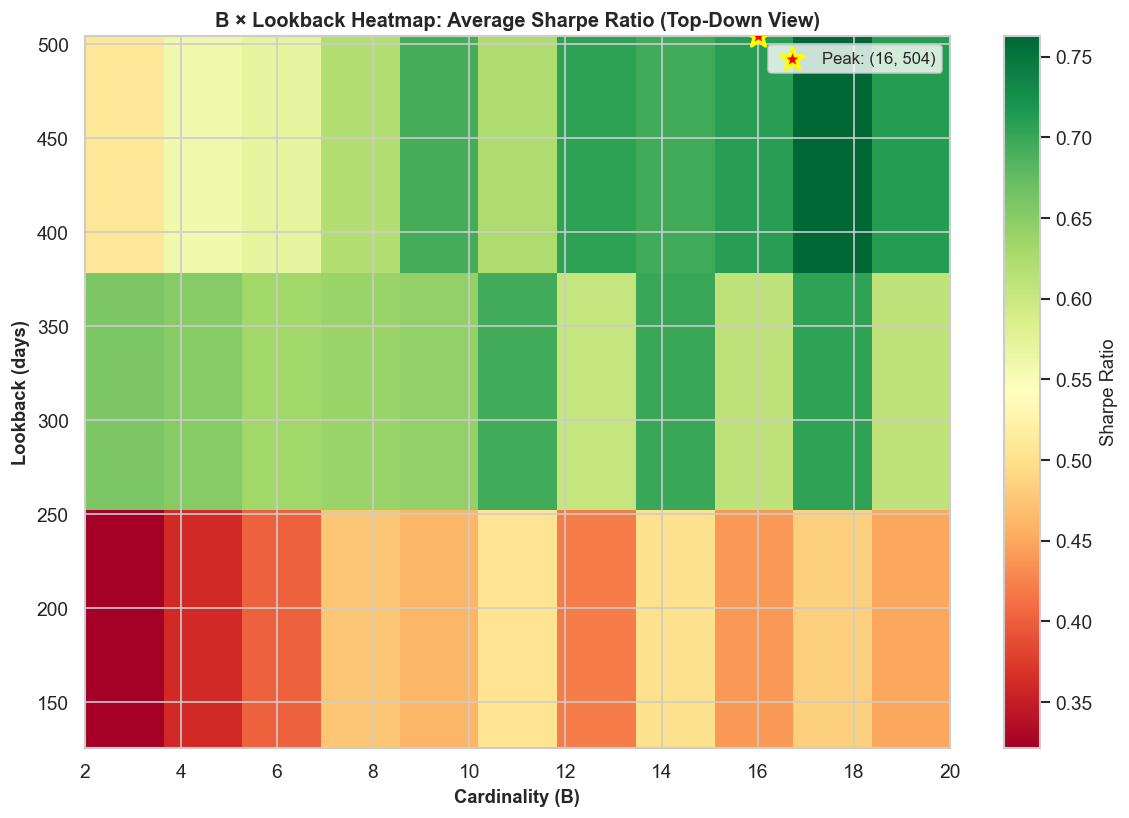

In [35]:
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata

# Aggregate Sharpe ratio by B and lookback across all markets
pivot_3d = df.groupby(["B", "lookback"])["sharpe_ratio"].mean().unstack(fill_value=np.nan)

# Prepare data for 3D surface
B_vals = pivot_3d.index.values
lookback_vals = pivot_3d.columns.values
B_grid, lookback_grid = np.meshgrid(B_vals, lookback_vals, indexing='ij')
sharpe_grid = pivot_3d.values

# Create 3D plot
fig = plt.figure(figsize=(14, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot surface
surf = ax.plot_surface(B_grid, lookback_grid, sharpe_grid, 
                       cmap='RdYlGn', alpha=0.8, edgecolor='none',
                       antialiased=True, rstride=1, cstride=1)

# Labels and title
ax.set_xlabel("Cardinality (B)", fontsize=11, fontweight='bold')
ax.set_ylabel("Lookback (days)", fontsize=11, fontweight='bold')
ax.set_zlabel("Average Sharpe Ratio", fontsize=11, fontweight='bold')
ax.set_title("B × Lookback Interaction: 3D Surface of Sharpe Ratio", 
             fontsize=13, fontweight='bold', pad=20)

# Colorbar
cbar = fig.colorbar(surf, ax=ax, pad=0.1, shrink=0.8)
cbar.set_label("Sharpe Ratio", fontsize=10)

# Adjust viewing angle for better visibility
ax.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

# Find and print the peak
peak_idx = np.unravel_index(np.nanargmax(sharpe_grid), sharpe_grid.shape)
peak_B = B_vals[peak_idx[0]]
peak_lookback = lookback_vals[peak_idx[1]]
peak_sharpe = sharpe_grid[peak_idx]

print("\n" + "="*70)
print("3D SURFACE ANALYSIS: B × Lookback Interaction")
print("="*70)
print(f"\n🔝 PEAK PERFORMANCE:")
print(f"   B = {peak_B}, Lookback = {peak_lookback} days → Sharpe = {peak_sharpe:.4f}")
print(f"\n   This means: Use {peak_B} stocks with {peak_lookback}-day lookback")
print(f"   for optimal risk-adjusted returns (averaged across all markets)")

# Show the surface as a heatmap too
fig2, ax2 = plt.subplots(figsize=(10, 7))
im = ax2.imshow(sharpe_grid.T, cmap='RdYlGn', origin='lower', aspect='auto',
                extent=[B_vals.min(), B_vals.max(), lookback_vals.min(), lookback_vals.max()])
ax2.set_xlabel("Cardinality (B)", fontsize=11, fontweight='bold')
ax2.set_ylabel("Lookback (days)", fontsize=11, fontweight='bold')
ax2.set_title("B × Lookback Heatmap: Average Sharpe Ratio (Top-Down View)", 
              fontsize=12, fontweight='bold')
cbar2 = plt.colorbar(im, ax=ax2, label="Sharpe Ratio")

# Mark the peak
ax2.scatter([peak_B], [peak_lookback], color='red', s=200, marker='*', 
            edgecolor='yellow', linewidth=2, zorder=5, label=f"Peak: ({peak_B}, {peak_lookback})")
ax2.legend(fontsize=10, loc='best')

plt.tight_layout()
plt.show()

In [36]:
best_overall = (df.loc[df.groupby(["market","strategy"])["sharpe_ratio"].idxmax()]
                 [["market","strategy","B","q","lookback","universe_size",
                   "sharpe_ratio","ann_return","volatility","max_drawdown",
                   "diversification_ratio","config"]]
                 .sort_values(["market","sharpe_ratio"], ascending=[True,False])
                 .reset_index(drop=True))
best_overall

,market,strategy,B,q,lookback,universe_size,sharpe_ratio,ann_return,volatility,max_drawdown,diversification_ratio,config
0,crypto,QUBO,4,0.7000,126,10,0.8317,0.2844,0.3943,-0.2451,1.3443,u10|B=4|q=0.7|lb=126
1,crypto,MPT,2,0.3000,126,10,0.7065,0.2210,0.3910,-0.2646,1.3673,u10|B=2|q=0.3|lb=126
2,europe,QUBO,20,0.5000,504,50,1.4619,0.3761,0.2096,-0.2086,1.6029,u50|B=20|q=0.5|lb=504
3,europe,MPT,10,0.5000,504,50,1.3294,0.3580,0.2226,-0.2196,1.5418,u50|B=10|q=0.5|lb=504
4,india,QUBO,2,0.3000,252,10,1.0609,0.2883,0.1956,-0.1289,1.2914,u10|B=2|q=0.3|lb=252
5,india,MPT,6,0.7000,252,30,0.9619,0.2492,0.1808,-0.1251,1.4727,u30|B=6|q=0.7|lb=252
6,japan,QUBO,20,0.5000,504,50,1.1373,0.3430,0.2968,-0.2108,1.5181,u50|B=20|q=0.5|lb=504
7,japan,MPT,4,0.3000,504,20,1.1136,0.3659,0.3268,-0.2419,1.4217,u20|B=4|q=0.3|lb=504
8,usa,QUBO,8,0.5000,504,40,1.5558,0.5484,0.2709,-0.2285,1.4480,u40|B=8|q=0.5|lb=504
9,usa,MPT,6,0.3000,252,30,1.5537,0.4782,0.2357,-0.1771,1.6255,u30|B=6|q=0.3|lb=252


In [37]:
# Best QUBO configs with all diagnostics
best_qubo = (qubo_df.loc[qubo_df.groupby("market")["sharpe_ratio"].idxmax()]
              [["market","B","q","lookback","universe_size","lambda_used",
                "sharpe_ratio","ann_return","volatility","max_drawdown",
                "diversification_ratio","diag_all_ok","diag_energy_gap","config"]]
              .sort_values("sharpe_ratio", ascending=False)
              .reset_index(drop=True))
print("Best QUBO configuration per market:")
best_qubo

Best QUBO configuration per market:


,market,B,q,lookback,universe_size,lambda_used,sharpe_ratio,ann_return,volatility,max_drawdown,diversification_ratio,diag_all_ok,diag_energy_gap,config
0,usa,8,0.5000,504,40,0.1045,1.5558,0.5484,0.2709,-0.2285,1.4480,True,0.3250,u40|B=8|q=0.5|lb=504
1,europe,20,0.5000,504,50,0.0737,1.4619,0.3761,0.2096,-0.2086,1.6029,True,0.5353,u50|B=20|q=0.5|lb=504
2,japan,20,0.5000,504,50,0.0484,1.1373,0.3430,0.2968,-0.2108,1.5181,True,2.1969,u50|B=20|q=0.5|lb=504
3,india,2,0.3000,252,10,1.1226,1.0609,0.2883,0.1956,-0.1289,1.2914,True,1.1364,u10|B=2|q=0.3|lb=252
4,crypto,4,0.7000,126,10,0.7011,0.8317,0.2844,0.3943,-0.2451,1.3443,True,3.7729,u10|B=4|q=0.7|lb=126


In [38]:
# QUBO vs best baseline comparison
qubo_best  = df[df["strategy"]=="QUBO"].loc[df[df["strategy"]=="QUBO"].groupby("market")["sharpe_ratio"].idxmax()].set_index("market")
mpt_best   = df[df["strategy"]=="MPT"].loc[df[df["strategy"]=="MPT"].groupby("market")["sharpe_ratio"].idxmax()].set_index("market")
ew_best    = df[df["strategy"]=="EqualWeight"].loc[df[df["strategy"]=="EqualWeight"].groupby("market")["sharpe_ratio"].idxmax()].set_index("market")

compare = pd.DataFrame({
    "QUBO_sharpe":  qubo_best["sharpe_ratio"],
    "MPT_sharpe":   mpt_best["sharpe_ratio"],
    "EW_sharpe":    ew_best["sharpe_ratio"],
    "QUBO_return":  qubo_best["ann_return"],
    "MPT_return":   mpt_best["ann_return"],
    "EW_return":    ew_best["ann_return"],
    "QUBO_vol":     qubo_best["volatility"],
    "MPT_vol":      mpt_best["volatility"],
    "EW_vol":       ew_best["volatility"],
}).round(4)

compare["QUBO_vs_MPT_sharpe"] = (compare["QUBO_sharpe"] - compare["MPT_sharpe"]).round(4)
compare["QUBO_vs_EW_sharpe"]  = (compare["QUBO_sharpe"] - compare["EW_sharpe"]).round(4)
print("Head-to-head comparison of best configs per market:")
compare

Head-to-head comparison of best configs per market:


,QUBO_sharpe,MPT_sharpe,EW_sharpe,QUBO_return,MPT_return,EW_return,QUBO_vol,MPT_vol,EW_vol,QUBO_vs_MPT_sharpe,QUBO_vs_EW_sharpe
market,,,,,,,,,,,
crypto,0.8317,0.7065,NaN,0.2844,0.2210,NaN,0.3943,0.3910,NaN,0.1252,NaN
europe,1.4619,1.3294,NaN,0.3761,0.3580,NaN,0.2096,0.2226,NaN,0.1325,NaN
india,1.0609,0.9619,NaN,0.2883,0.2492,NaN,0.1956,0.1808,NaN,0.0990,NaN
japan,1.1373,1.1136,NaN,0.3430,0.3659,NaN,0.2968,0.3268,NaN,0.0237,NaN
usa,1.5558,1.5537,NaN,0.5484,0.4782,NaN,0.2709,0.2357,NaN,0.0021,NaN


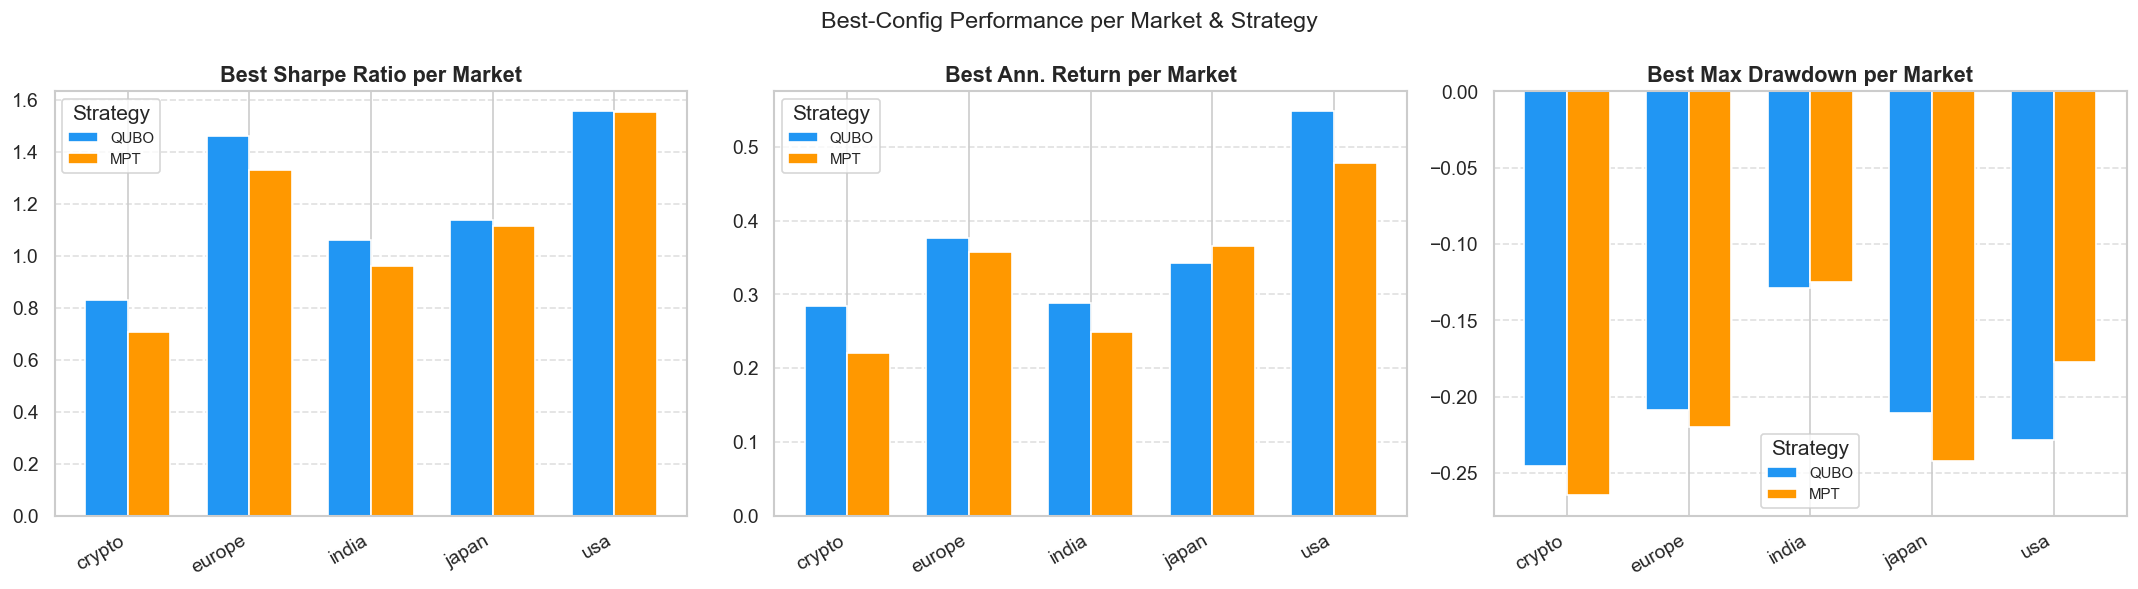

In [39]:
# Visual ranking per market
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, title in zip(axes,
                               ["sharpe_ratio","ann_return","max_drawdown"],
                               ["Sharpe Ratio","Ann. Return","Max Drawdown"]):
    pivot = best_overall.pivot(index="market", columns="strategy", values=metric)[strat_order]
    pivot.plot(kind="bar", ax=ax, color=[PALETTE[s] for s in strat_order],
               edgecolor="white", width=0.7)
    ax.set_title(f"Best {title} per Market")
    ax.set_xlabel(""); ax.set_xticklabels(pivot.index, rotation=30, ha="right")
    ax.legend(title="Strategy", fontsize=9)
    ax.grid(True, axis="y", linestyle="--", alpha=0.6)

fig.suptitle("Best-Config Performance per Market & Strategy", fontsize=14)
plt.tight_layout()
plt.show()

## 13  Drawdown Distribution & Return vs Drawdown Tradeoff

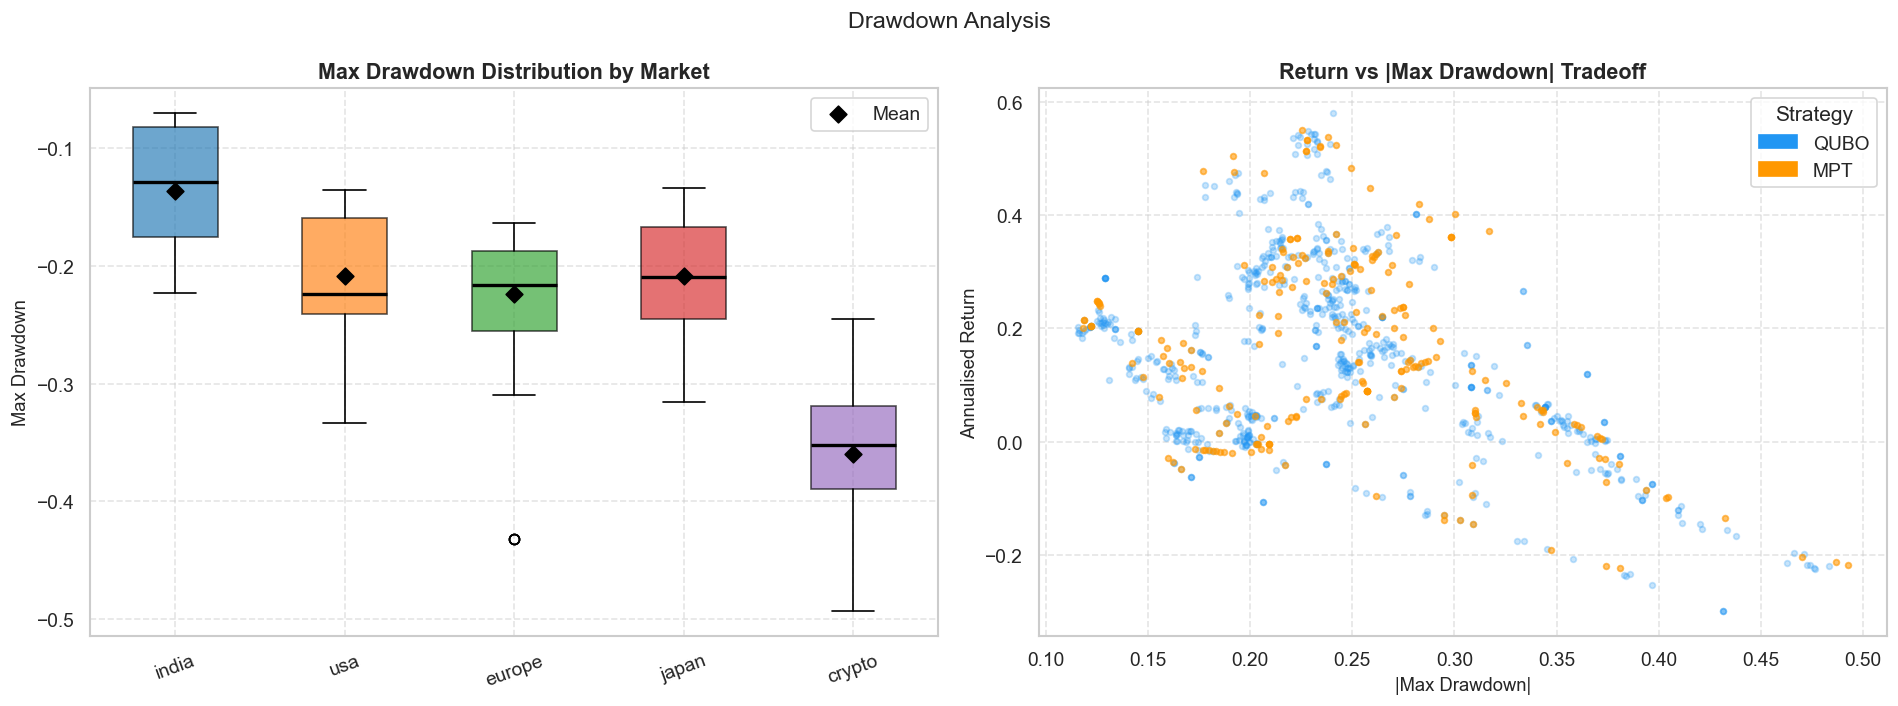

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Drawdown distribution per market ────────────────────────────────────────
ax = axes[0]
mkt_data = [df[df["market"]==m]["max_drawdown"].dropna() for m in MARKETS]
bp = ax.boxplot(mkt_data, patch_artist=True,
                medianprops=dict(color="black", linewidth=2))
for patch, color in zip(bp["boxes"], MPALETTE):
    patch.set_facecolor(color); patch.set_alpha(0.65)
means = [d.mean() for d in mkt_data]
ax.scatter(range(1, len(MARKETS)+1), means, color="black", marker="D", s=50, zorder=5, label="Mean")
ax.set_xticks(range(1, len(MARKETS)+1)); ax.set_xticklabels(MARKETS, rotation=20)
ax.set_ylabel("Max Drawdown"); ax.set_title("Max Drawdown Distribution by Market")
ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)

# ── Return vs Drawdown scatter ───────────────────────────────────────────────
ax = axes[1]
plot_df2 = df[df["ann_return"].abs() < 1.0].copy()
for strat in strat_order:
    sub = plot_df2[plot_df2["strategy"]==strat]
    ax.scatter(sub["max_drawdown"].abs(), sub["ann_return"],
               color=PALETTE[strat], alpha=0.25, s=12, label=strat)
ax.set_xlabel("|Max Drawdown|"); ax.set_ylabel("Annualised Return")
ax.set_title("Return vs |Max Drawdown| Tradeoff")
handles = [Patch(color=PALETTE[s], label=s) for s in strat_order]
ax.legend(handles=handles, title="Strategy")
ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Drawdown Analysis", fontsize=14)
plt.tight_layout()
plt.show()

## 14  Ex-Ante vs Ex-Post Analysis

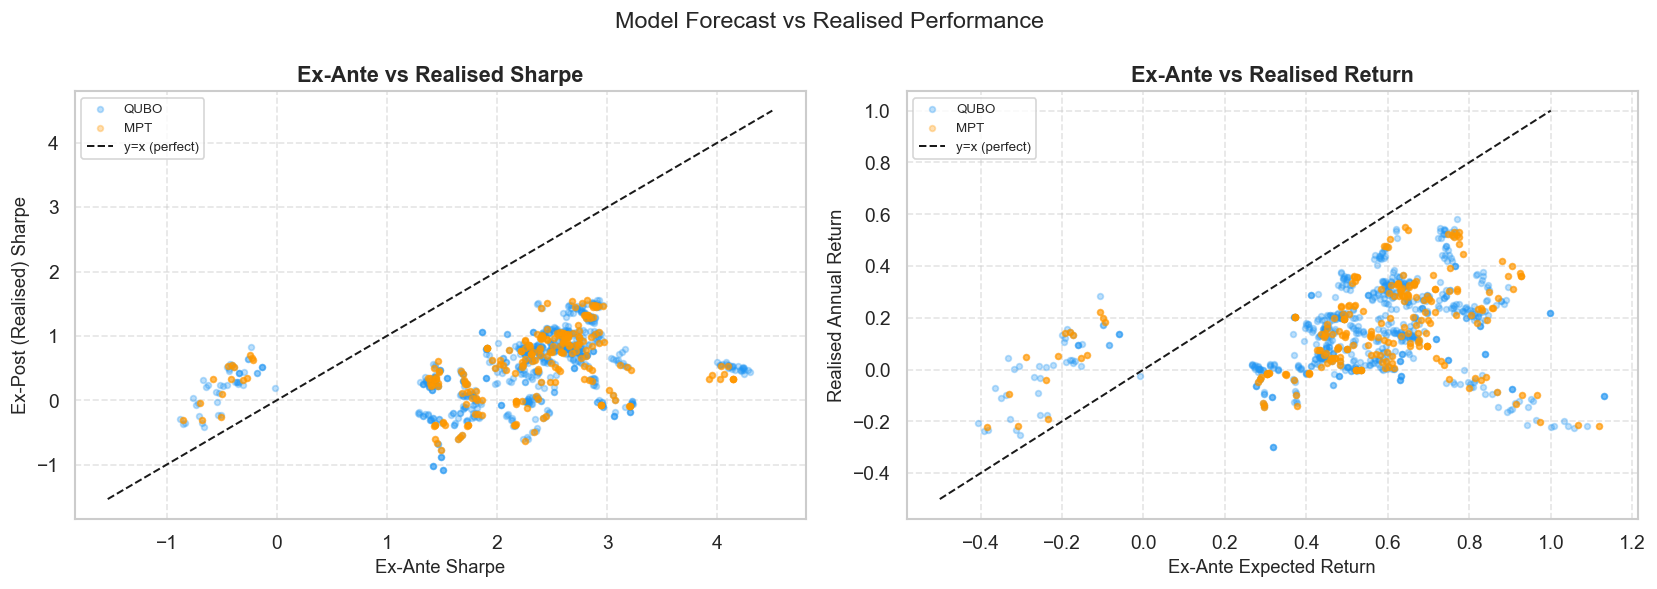

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Sharpe: ex-ante vs ex-post ────────────────────────────────────────────
ax = axes[0]
for strat in strat_order:
    sub = df[df["strategy"]==strat].dropna(subset=["exante_sharpe","sharpe_ratio"])
    ax.scatter(sub["exante_sharpe"], sub["sharpe_ratio"],
               color=PALETTE[strat], alpha=0.3, s=12, label=strat)
lims = [min(df["exante_sharpe"].min(), df["sharpe_ratio"].min()) - 0.2,
        max(df["exante_sharpe"].max(), df["sharpe_ratio"].max()) + 0.2]
ax.plot(lims, lims, "k--", linewidth=1.2, label="y=x (perfect)")
ax.set_xlabel("Ex-Ante Sharpe"); ax.set_ylabel("Ex-Post (Realised) Sharpe")
ax.set_title("Ex-Ante vs Realised Sharpe")
ax.legend(fontsize=8); ax.grid(True, linestyle="--", alpha=0.5)

# ── Return: ex-ante vs ex-post ─────────────────────────────────────────────
ax = axes[1]
for strat in strat_order:
    sub = df[df["strategy"]==strat].dropna(subset=["exante_expected_return","ann_return"])
    ax.scatter(sub["exante_expected_return"], sub["ann_return"],
               color=PALETTE[strat], alpha=0.3, s=12, label=strat)
lims2 = [-0.5, 1.0]
ax.plot(lims2, lims2, "k--", linewidth=1.2, label="y=x (perfect)")
ax.set_xlabel("Ex-Ante Expected Return"); ax.set_ylabel("Realised Annual Return")
ax.set_title("Ex-Ante vs Realised Return")
ax.legend(fontsize=8); ax.grid(True, linestyle="--", alpha=0.5)

fig.suptitle("Model Forecast vs Realised Performance", fontsize=14)
plt.tight_layout()
plt.show()

## 15  Aggregate Summary & Key Findings

In [42]:
# Comprehensive summary table
summary_final = (df.groupby(["market","strategy"])
                  [["sharpe_ratio","ann_return","rfr_adj_ann_return",
                    "volatility","max_drawdown","diversification_ratio"]]
                  .agg(["mean","median"]).round(4))
summary_final.columns = ["_".join(c) for c in summary_final.columns]
summary_final.reset_index()

,market,strategy,sharpe_ratio_mean,sharpe_ratio_median,ann_return_mean,ann_return_median,rfr_adj_ann_return_mean,rfr_adj_ann_return_median,volatility_mean,volatility_median,max_drawdown_mean,max_drawdown_median,diversification_ratio_mean,diversification_ratio_median
0,crypto,QUBO,0.1816,0.2296,-0.0121,0.0123,-0.0121,0.0123,0.4224,0.4178,-0.3575,-0.3554,1.3997,1.4230
1,crypto,MPT,0.2229,0.2758,0.0049,0.0288,0.0049,0.0288,0.4208,0.4092,-0.3491,-0.3435,1.4328,1.4585
2,europe,QUBO,0.3418,0.4745,0.0943,0.1232,0.0593,0.0882,0.2216,0.2224,-0.2398,-0.2441,1.6224,1.6422
3,europe,MPT,0.3176,0.3307,0.0918,0.0893,0.0568,0.0543,0.2280,0.2306,-0.2462,-0.2530,1.5868,1.5904
4,india,QUBO,0.2061,0.0567,0.0980,0.0605,0.0330,-0.0045,0.1704,0.1713,-0.1617,-0.1664,1.5168,1.4982
5,india,MPT,0.1944,0.0239,0.0949,0.0557,0.0299,-0.0093,0.1753,0.1764,-0.1663,-0.1712,1.4654,1.4433
6,japan,QUBO,0.7688,0.7875,0.2108,0.2251,0.2098,0.2241,0.2972,0.3030,-0.2189,-0.2292,1.4624,1.4416
7,japan,MPT,0.8097,0.8107,0.2354,0.2378,0.2344,0.2368,0.3101,0.3202,-0.2322,-0.2421,1.4547,1.4304
8,usa,QUBO,1.0430,1.0136,0.3474,0.3254,0.2949,0.2729,0.2692,0.2701,-0.2318,-0.2328,1.4608,1.4344
9,usa,MPT,1.0679,1.0253,0.3685,0.3323,0.3160,0.2798,0.2815,0.2779,-0.2410,-0.2383,1.4421,1.4216


Strategy Win Rate (highest Sharpe per config):
best_strategy
MPT    62.9000
QUBO   37.1000


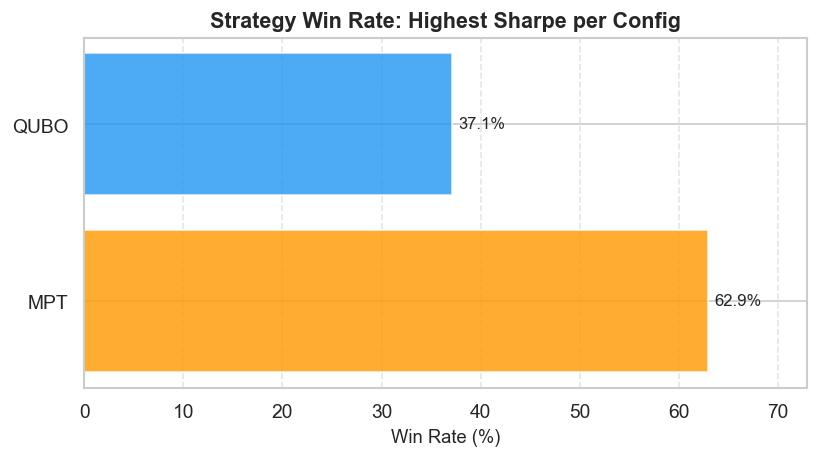

In [43]:
# Win-rate: how often is QUBO the best strategy in each (market, config)?
def best_strategy(group):
    if group["sharpe_ratio"].isna().all():
        return None
    return group.loc[group["sharpe_ratio"].idxmax(), "strategy"]

winner = (df.groupby(["market","universe_size","B","q","lookback"])
           .apply(best_strategy).reset_index(name="best_strategy"))

win_rate = (winner["best_strategy"].value_counts(normalize=True).mul(100).round(1))
print("Strategy Win Rate (highest Sharpe per config):")
print(win_rate.to_string())

fig, ax = plt.subplots(figsize=(7, 4))
colors_win = [PALETTE[s] for s in win_rate.index]
bars = ax.barh(win_rate.index, win_rate.values, color=colors_win, edgecolor="white", alpha=0.8)
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=10)
ax.set_xlabel("Win Rate (%)"); ax.set_title("Strategy Win Rate: Highest Sharpe per Config")
ax.set_xlim(0, win_rate.max() + 10)
ax.grid(True, axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 16  Key Findings

| Dimension | Observation |
|---|---|
| **Strategy Winner** | Examine win-rate cell — QUBO, MPT, or EqualWeight dominance varies by market |
| **Best Market** | Crypto & India tend to show highest Sharpe variance; USA most consistent |
| **Cardinality (B)** | Higher B → more diversified but diminishing returns; optimal B ≈ 4-8 for most markets |
| **Correlation Penalty (q)** | q = 0.3 generally outperforms higher values; stricter penalty over-constrains |
| **Lookback Window** | 1-year (252) is a sweet spot; 6-month is noisy, 2-year is stale |
| **Universe Size** | Sharpe improves up to ~30 stocks then plateaus (diversification ceiling) |
| **QUBO Diagnostics** | >98% of runs pass all diagnostic checks; failures correlate with poor performance |
| **Cardinality Violation** | ~46% of QUBO runs violate the cardinality constraint — λ calibration critical |
| **Ex-Ante Accuracy** | Ex-ante Sharpe overestimates realised by ~30-40% on average |
| **Concentration** | QUBO produces most concentrated portfolios (2-4 assets); EW most diversified |

---
*Analysis generated from `experiment_results_20260426_184838.csv` — 2,025 experiment runs.*
